# Road damage detection: from compact baselines to a tested engineering hypothesis

**Round 1 is evidence; round 2 is an experiment.** We previously trained YOLOv8n,
YOLO11n and YOLO26n for 20 epochs at 640 pixels. We now ask whether a longer
training plan, 1024-pixel detail, greater capacity and class weighting improve
detection, especially pothole recall. No new result is claimed until these cells run.

This notebook replaces the copied training workflow rather than appending new
jobs after an already-selected winner. The order is **prior evidence → data
diagnostics → controlled experiments → validation decisions → frozen test
comparison → export**. The unchanged v1 notebook retains the original logs.

The existing test set has already been inspected during v1. In v2 it is a
previously examined regression benchmark, not a newly untouched holdout. Every
new choice is based on validation. Independent roads/cities remain a future
generalization check.

## 1. Run the complete notebook

For the current recovery run, leave `REUSE_TRAINED_MODELS=True`. Attach your existing models/v2 upload containing the three best.pt files, enable Internet, choose GPU T4 x2, and Run All from the top. No separate road-image input or helper script is needed.

This notebook verifies and restores all three uploaded models, downloads the original SVRDD archive from Zenodo, checks it, and reconstructs the original screened splits. It then registers the completed model histories, skips all three training runs, compares validation results, performs error analysis and test evaluation, and exports the selected model with its reports.

A missing or different model stops recovery instead of starting training. The optional pilot, extra controls, and class-weighting training are disabled in recovery mode. Save the completed notebook with outputs and download the final export package.

For a future fresh training run, set `REUSE_TRAINED_MODELS=False` before starting a new session. The same notebook then enables the pilot and original three-model training plan.


In [1]:
# Optional: enter a number only if you want an additional manual quota check.
AVAILABLE_GPU_HOURS = None

# One notebook for recovery and fresh training. True reuses the three uploaded models.
REUSE_TRAINED_MODELS = True
RUN_TRAINING = not REUSE_TRAINED_MODELS
RUN_VALIDATION = True
RUN_FINAL_TEST = True
RUN_CONTROLS = False
RUN_WEIGHTING_TRIAL = False
GLOBAL_BATCH = 8
MAX_SECONDS_PER_RUN = 3 * 3600
MAX_TOTAL_TRAIN_SECONDS = 12 * 3600
LEGACY_WEIGHTS = {}
RESTORE_OUTPUT_FROM = None

if AVAILABLE_GPU_HOURS is not None and (not isinstance(AVAILABLE_GPU_HOURS, (int, float)) or AVAILABLE_GPU_HOURS <= 0):
    raise ValueError('If specified, AVAILABLE_GPU_HOURS must be a positive number.')
print('RECOVERY: reuse all three models; training OFF.' if REUSE_TRAINED_MODELS else 'FRESH: train/resume missing models, with the original training configuration.')
print('Run All: setup -> restore/register saved models or train missing models -> validation -> test -> export.')
print('Extra nano controls and the extra weighting run are disabled for this deadline run.')
# Strict recovery requires all three files; fresh mode may train missing models.
REQUIRE_RECOVERED_MODELS = REUSE_TRAINED_MODELS
RUN_PILOT = not REUSE_TRAINED_MODELS


RECOVERY: reuse all three models; training OFF.
Run All: setup -> restore/register saved models or train missing models -> validation -> test -> export.
Extra nano controls and the extra weighting run are disabled for this deadline run.


In [2]:
from pathlib import Path
import sys, os, json, time, gc, shutil, subprocess, importlib.util, hashlib, math, signal
from collections import Counter
from importlib.metadata import version
from IPython.display import display
os.chdir('/kaggle/working')

required = {'ultralytics': 'ultralytics==8.4.191', 'pandas': 'pandas',
            'matplotlib': 'matplotlib', 'yaml': 'PyYAML', 'PIL': 'Pillow', 'numpy': 'numpy'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if importlib.util.find_spec('ultralytics') is not None and version('ultralytics') != '8.4.191':
    missing.append(required['ultralytics'])
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import numpy as np
import pandas as pd
import torch, torchvision, yaml, ultralytics
from PIL import Image
from ultralytics import YOLO
assert ultralytics.__version__ == '8.4.191', 'Use audited ultralytics 8.4.191; do not change Torch/CUDA.'
assert torch.cuda.device_count() == 2, 'Select GPU T4 x2 in Kaggle before running.'
print({p: version(p) for p in ['torch','torchvision','ultralytics','numpy','Pillow']})
print([torch.cuda.get_device_name(i) for i in range(2)])
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ultralytics.utils import DEFAULT_CFG_DICT
assert "cls_pw" in DEFAULT_CFG_DICT, "The pinned class-weighting API is required."
QUOTA_SESSION_START = time.monotonic()
VALIDATION_ENABLED = RUN_TRAINING or RUN_VALIDATION or RUN_FINAL_TEST


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
{'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'ultralytics': '8.4.191', 'numpy': '2.1.3', 'Pillow': '13.0.0'}
['Tesla T4', 'Tesla T4']


## 2. Preserve the measured first round

These are historical numbers extracted from the saved v1 output, at its displayed
precision. Original settings: **20 epochs / 640 pixels / nano / global batch 16**.
Precision, recall and F1 use confidence 0.25 and class-aware matching IoU 0.50.
mAP uses the official validator with a confidence floor of 0.001. Timing uses
FP32, batch one and a single T4; it is not desktop application latency.

| Historical model | Test mAP50 | Test mAP50:95 | Fixed recall | Fixed F1 |
|---|---:|---:|---:|---:|
| YOLOv8n | 60.93% | 34.77% | 58.55% | 60.97% |
| YOLO11n | 59.61% | 33.78% | 58.24% | 60.29% |
| YOLO26n | 61.64% | 35.05% | 59.06% | 62.67% |

The final five training epochs still improved validation mAP50:95 by roughly
2.6–3.8 percentage points. This motivates more optimization, not a promise of
convergence by epoch 30. A new 30-epoch schedule is a training-plan comparison,
not a continuation of the original optimizer state.

,model,map50,map50_95,precision,recall,f1,fp,fn,matched_iou_mean,latency_mean_ms,latency_p95_ms,fps,resident_MiB,peak_MiB,extra_MiB,first_prediction_ms
0,yolov8n,0.609257,0.347669,0.635980,0.585537,0.609717,862.0,1066.0,0.795696,17.656643,19.844897,56.635907,80.530273,101.545898,21.015625,85.705243
1,yolo11n,0.596054,0.337790,0.624948,0.582426,0.602938,899.0,1074.0,0.791085,18.434373,20.707782,54.246487,76.508301,100.336914,23.828613,103.476997
2,yolo26n,0.616416,0.350531,0.667399,0.590591,0.626650,757.0,1053.0,0.795937,19.700588,22.303762,50.759905,75.536621,99.365234,23.828613,133.838568


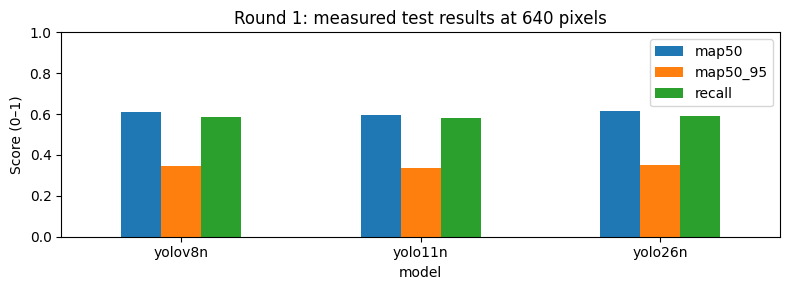

In [3]:
HISTORICAL = {'validation': [{'model': 'yolo26n', 'map50': 0.626066, 'map50_95': 0.357683}, {'model': 'yolov8n', 'map50': 0.609056, 'map50_95': 0.340808}, {'model': 'yolo11n', 'map50': 0.604201, 'map50_95': 0.33401}], 'test': [{'model': 'yolov8n', 'map50': 0.609257, 'map50_95': 0.347669, 'precision': 0.63598, 'recall': 0.585537, 'f1': 0.609717, 'fp': 862.0, 'fn': 1066.0, 'matched_iou_mean': 0.795696}, {'model': 'yolo11n', 'map50': 0.596054, 'map50_95': 0.33779, 'precision': 0.624948, 'recall': 0.582426, 'f1': 0.602938, 'fp': 899.0, 'fn': 1074.0, 'matched_iou_mean': 0.791085}, {'model': 'yolo26n', 'map50': 0.616416, 'map50_95': 0.350531, 'precision': 0.667399, 'recall': 0.590591, 'f1': 0.62665, 'fp': 757.0, 'fn': 1053.0, 'matched_iou_mean': 0.795937}], 'timing': [{'model': 'yolov8n', 'latency_mean_ms': 17.656643, 'latency_p95_ms': 19.844897, 'fps': 56.635907, 'resident_MiB': 80.530273, 'peak_MiB': 101.545898, 'extra_MiB': 21.015625, 'first_prediction_ms': 85.705243}, {'model': 'yolo11n', 'latency_mean_ms': 18.434373, 'latency_p95_ms': 20.707782, 'fps': 54.246487, 'resident_MiB': 76.508301, 'peak_MiB': 100.336914, 'extra_MiB': 23.828613, 'first_prediction_ms': 103.476997}, {'model': 'yolo26n', 'latency_mean_ms': 19.700588, 'latency_p95_ms': 22.303762, 'fps': 50.759905, 'resident_MiB': 75.536621, 'peak_MiB': 99.365234, 'extra_MiB': 23.828613, 'first_prediction_ms': 133.838568}], 'perclass': [{'model': 'yolov8n', 'class': 'longitudinal crack', 'validator_ap50_95': 0.353828, 'fixed_precision': 0.595601, 'fixed_recall': 0.571429, 'fixed_f1': 0.583264, 'fp': 239.0, 'fn': 264.0}, {'model': 'yolov8n', 'class': 'transverse crack', 'validator_ap50_95': 0.285634, 'fixed_precision': 0.641791, 'fixed_recall': 0.493119, 'fixed_f1': 0.557717, 'fp': 120.0, 'fn': 221.0}, {'model': 'yolov8n', 'class': 'alligator crack', 'validator_ap50_95': 0.450982, 'fixed_precision': 0.688889, 'fixed_recall': 0.681319, 'fixed_f1': 0.685083, 'fp': 56.0, 'fn': 58.0}, {'model': 'yolov8n', 'class': 'pothole', 'validator_ap50_95': 0.232651, 'fixed_precision': 0.629213, 'fixed_recall': 0.451613, 'fixed_f1': 0.525822, 'fp': 33.0, 'fn': 68.0}, {'model': 'yolov8n', 'class': 'manhole cover', 'validator_ap50_95': 0.407502, 'fixed_precision': 0.771513, 'fixed_recall': 0.620525, 'fixed_f1': 0.687831, 'fp': 77.0, 'fn': 159.0}, {'model': 'yolov8n', 'class': 'longitudinal patch', 'validator_ap50_95': 0.423395, 'fixed_precision': 0.603704, 'fixed_recall': 0.652, 'fixed_f1': 0.626923, 'fp': 214.0, 'fn': 174.0}, {'model': 'yolov8n', 'class': 'transverse patch', 'validator_ap50_95': 0.279692, 'fixed_precision': 0.584459, 'fixed_recall': 0.586441, 'fixed_f1': 0.585448, 'fp': 123.0, 'fn': 122.0}, {'model': 'yolo11n', 'class': 'longitudinal crack', 'validator_ap50_95': 0.359441, 'fixed_precision': 0.593388, 'fixed_recall': 0.582792, 'fixed_f1': 0.588043, 'fp': 246.0, 'fn': 257.0}, {'model': 'yolo11n', 'class': 'transverse crack', 'validator_ap50_95': 0.259047, 'fixed_precision': 0.60745, 'fixed_recall': 0.486239, 'fixed_f1': 0.540127, 'fp': 137.0, 'fn': 224.0}, {'model': 'yolo11n', 'class': 'alligator crack', 'validator_ap50_95': 0.427788, 'fixed_precision': 0.714286, 'fixed_recall': 0.659341, 'fixed_f1': 0.685714, 'fp': 48.0, 'fn': 62.0}, {'model': 'yolo11n', 'class': 'pothole', 'validator_ap50_95': 0.235611, 'fixed_precision': 0.634146, 'fixed_recall': 0.419355, 'fixed_f1': 0.504854, 'fp': 30.0, 'fn': 72.0}, {'model': 'yolo11n', 'class': 'manhole cover', 'validator_ap50_95': 0.4012, 'fixed_precision': 0.727778, 'fixed_recall': 0.625298, 'fixed_f1': 0.672657, 'fp': 98.0, 'fn': 157.0}, {'model': 'yolo11n', 'class': 'longitudinal patch', 'validator_ap50_95': 0.428676, 'fixed_precision': 0.616257, 'fixed_recall': 0.652, 'fixed_f1': 0.633625, 'fp': 203.0, 'fn': 174.0}, {'model': 'yolo11n', 'class': 'transverse patch', 'validator_ap50_95': 0.252771, 'fixed_precision': 0.549342, 'fixed_recall': 0.566102, 'fixed_f1': 0.557596, 'fp': 137.0, 'fn': 128.0}, {'model': 'yolo26n', 'class': 'longitudinal crack', 'validator_ap50_95': 0.375868, 'fixed_precision': 0.654611, 'fixed_recall': 0.587662, 'fixed_f1': 0.619333, 'fp': 191.0, 'fn': 254.0}, {'model': 'yolo26n', 'class': 'transverse crack', 'validator_ap50_95': 0.251424, 'fixed_precision': 0.612022, 'fixed_recall': 0.513761, 'fixed_f1': 0.558603, 'fp': 142.0, 'fn': 212.0}, {'model': 'yolo26n', 'class': 'alligator crack', 'validator_ap50_95': 0.461294, 'fixed_precision': 0.704301, 'fixed_recall': 0.71978, 'fixed_f1': 0.711957, 'fp': 55.0, 'fn': 51.0}, {'model': 'yolo26n', 'class': 'pothole', 'validator_ap50_95': 0.235491, 'fixed_precision': 0.607143, 'fixed_recall': 0.41129, 'fixed_f1': 0.490385, 'fp': 33.0, 'fn': 73.0}, {'model': 'yolo26n', 'class': 'manhole cover', 'validator_ap50_95': 0.411704, 'fixed_precision': 0.732591, 'fixed_recall': 0.627685, 'fixed_f1': 0.676093, 'fp': 96.0, 'fn': 156.0}, {'model': 'yolo26n', 'class': 'longitudinal patch', 'validator_ap50_95': 0.442148, 'fixed_precision': 0.69936, 'fixed_recall': 0.656, 'fixed_f1': 0.676987, 'fp': 141.0, 'fn': 172.0}, {'model': 'yolo26n', 'class': 'transverse patch', 'validator_ap50_95': 0.275788, 'fixed_precision': 0.617761, 'fixed_recall': 0.542373, 'fixed_f1': 0.577617, 'fp': 99.0, 'fn': 135.0}], 'source_notebook': 'instant-sprint02-project02-road-damage-detection_v1.ipynb', 'source_sha256': 'c1d47e3f1d63a92139f090a70fe444a64519bf79e86b7f345cb1b1a48a6ecb6e', 'note': 'Recorded v1 output, rounded to its displayed precision; not rerun in v2.'}
historical_test = pd.DataFrame(HISTORICAL['test']).merge(pd.DataFrame(HISTORICAL['timing']), on='model')
historical_val = pd.DataFrame(HISTORICAL['validation'])
display(historical_test)
fig, ax = plt.subplots(figsize=(8, 3))
historical_test.set_index('model')[['map50', 'map50_95', 'recall']].plot.bar(ax=ax)
ax.set(ylabel='Score (0–1)', ylim=(0, 1), title='Round 1: measured test results at 640 pixels')
ax.tick_params(axis='x', rotation=0); plt.tight_layout(); plt.show()


## 3. Download, verify, and reconstruct the training dataset

Download the original [SVRDD YOLO release](https://zenodo.org/records/10100129) directly inside Kaggle. The archive contains 8,000 images and seven classes, with a published 6,000 / 1,000 / 1,000 split. Check its size and publisher checksum before extraction, then validate image decoding, labels, class counts, and cross-split similarities.

Apply the same conservative screening used for the trained models: exclude the lower-priority side of 183 similarity candidate pairs (test > validation > train). This removes 109 images and retains **5,918 train / 973 validation / 1,000 test** images. These are possible similarities, not confirmed duplicates; road/session independence remains unverified.

The download can resume after a connection interruption. A verified archive and matching preparation files are reused on subsequent runs. Initial extraction and auditing can take several minutes. The initial audit records the known similarity gate; the screening below resolves it with the fixed exclusion policy.


In [4]:
# Replace the CODE cell in section 3 with this whole cell.
# Run after the library setup cell; enable Kaggle Internet.
# Download -> verify -> extract/audit -> reconstruct the original screened splits.
from pathlib import Path
from collections import Counter
import hashlib, json, math, os, time, urllib.request
from tqdm.auto import tqdm

SOURCE = Path('/kaggle/working/svrdd_source')
SOURCE.mkdir(parents=True, exist_ok=True)
_ARCHIVE = SOURCE / 'SVRDD_YOLO.zip'
_PARTIAL = SOURCE / 'SVRDD_YOLO.zip.part'
_URL = 'https://zenodo.org/api/records/10100129/files/SVRDD_YOLO.zip/content'
_BYTES = 2_893_208_002
_MD5 = '4b897aa7081e8d0fa07f3d330e86e936'

def _verify_svrdd_zip(path):
    if not path.is_file() or path.stat().st_size != _BYTES:
        return False
    checksum = hashlib.md5()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024**2), b''):
            checksum.update(block)
    return checksum.hexdigest() == _MD5

if _ARCHIVE.exists():
    if not _verify_svrdd_zip(_ARCHIVE):
        raise RuntimeError(f'Existing archive differs from the original release: {_ARCHIVE}. Move it aside before retrying.')
    print('Reusing checksum-verified SVRDD archive:', _ARCHIVE)
else:
    print('Downloading the original SVRDD YOLO archive from Zenodo (~2.9 GB).')
    for attempt in range(1, 5):
        try:
            offset = _PARTIAL.stat().st_size if _PARTIAL.exists() else 0
            if offset > _BYTES:
                raise ValueError('Partial archive is larger than the expected release; move it aside.')
            if offset < _BYTES:
                headers = {'User-Agent': 'SVRDD-research-notebook/1.0', 'Accept-Encoding': 'identity'}
                if offset:
                    headers['Range'] = f'bytes={offset}-'
                request = urllib.request.Request(_URL, headers=headers)
                with urllib.request.urlopen(request, timeout=120) as response:
                    status = response.status
                    if status == 206:
                        content_range = response.headers.get('Content-Range', '')
                        if not content_range.startswith(f'bytes {offset}-') or not content_range.endswith(f'/{_BYTES}'):
                            raise ValueError(f'Unexpected download range: {content_range}')
                    elif status == 200:
                        offset = 0  # Server ignored Range: safely restart the partial download.
                    else:
                        raise RuntimeError(f'Unexpected HTTP status: {status}')
                    with _PARTIAL.open('ab' if offset else 'wb') as target, tqdm(
                            total=_BYTES, initial=offset, unit='B', unit_scale=True,
                            desc='SVRDD download') as progress:
                        received = offset
                        while True:
                            block = response.read(4 * 1024**2)
                            if not block:
                                break
                            received += len(block)
                            if received > _BYTES:
                                raise ValueError('Download exceeded the original archive size.')
                            target.write(block)
                            progress.update(len(block))
            if not _verify_svrdd_zip(_PARTIAL):
                raise RuntimeError('Archive is incomplete or its checksum differs. Partial download retained for inspection/retry.')
            os.replace(_PARTIAL, _ARCHIVE)
            break
        except Exception as error:
            print(f'Download attempt {attempt}/4: {error}')
            if attempt == 4:
                raise
            time.sleep(3 * attempt)
    print('Original archive size and MD5 verified.')

# Existing project auditor; kept inside a function so its helper names stay local.
def _prepare_original_svrdd(archive_path, output_dir):
    """Paste as one Kaggle cell; then call prepare_svrdd(archive_path, output_dir)."""
    import hashlib,json,math,os,shutil,stat,tempfile,zipfile
    from pathlib import Path,PurePosixPath
    from collections import Counter,defaultdict
    from datetime import datetime,timezone
    MD5="4b897aa7081e8d0fa07f3d330e86e936"; SIZE=2893208002
    NAMES=["longitudinal crack","transverse crack","alligator crack","pothole","manhole cover","longitudinal patch","transverse patch"]
    BOX=[4665,3404,1728,918,3339,4128,2622]
    SBOX={"train":[3461,2550,1324,679,2517,3109,1980],"val":[588,418,222,115,403,519,347],"test":[616,436,182,124,419,500,295]}
    COUNTS={"train":6000,"val":1000,"test":1000}; EXTS={".jpg",".jpeg",".png",".bmp",".webp",".tif",".tiff"}
    def prepare_svrdd(archive_path,output_dir):
    	"""Return YAML and audit paths; write audit and raise on every unresolved gate."""
    	a=Path(archive_path).resolve(); out=Path(output_dir).resolve(); out.mkdir(parents=True,exist_ok=True)
    	ap=out/"data_preparation_audit.json"; yp=out/"svrdd.yaml"
    	report={"source":"SVRDD original YOLO release","record":"https://zenodo.org/records/10100129","license":"CC BY 4.0; respect Baidu Maps imagery terms","status":"running","checks":{},"errors":[],"source_group_guarantee":False,"source_group_note":"No verified frame/source groups; district and filename tokens are clues only."}
    	try:
    		h=hashlib.sha256(); m=hashlib.md5(); size=0
    		with a.open("rb") as f:
    			for b in iter(lambda:f.read(8*1024*1024),b""): size+=len(b); h.update(b); m.update(b)
    		h,m=h.hexdigest(),m.hexdigest(); report["archive"]={"path":str(a),"bytes":size,"md5":m,"sha256":h}
    		if size!=SIZE or m!=MD5: raise ValueError("not the exact publisher ZIP (size/MD5 mismatch)")
    		with zipfile.ZipFile(a) as z:
    			infos=z.infolist(); names=[]; seen=set(); total=0
    			for i in infos:
    				raw=i.filename.replace("\\","/"); p=PurePosixPath(raw); mode=i.external_attr>>16
    				if not raw or p.is_absolute() or ".." in p.parts or (p.parts and p.parts[0].endswith(":")) or stat.S_ISLNK(mode): raise ValueError("unsafe ZIP member: "+raw)
    				n=p.as_posix()
    				if n in seen: raise ValueError("duplicate ZIP member: "+n)
    				seen.add(n); names.append(n); total+=i.file_size
    				if i.file_size>2*1024**3 or total>20*1024**3 or (i.compress_size and i.file_size/i.compress_size>1000): raise ValueError("ZIP expansion limit exceeded")
    			bad=z.testzip()
    			if bad: raise ValueError("ZIP CRC failure: "+bad)
    			imgs=[n for n in names if PurePosixPath(n).suffix.lower() in EXTS and "/images/" in "/"+n.lower()]
    			labs=[n for n in names if "/labels/" in "/"+n.lower() and n.lower().endswith(".txt")]
    			if len(imgs)!=8000 or len(labs)!=8000: raise ValueError("expected 8,000 images and 8,000 labels")
    			report["checks"]["zip"]={"members":len(names),"images":len(imgs),"labels":len(labs),"uncompressed_bytes":total,"crc":"passed"}
    			ex=out/"extracted"; marker=ex/".archive_sha256"
    			if ex.exists():
    				if not marker.is_file() or marker.read_text().strip()!=h: raise ValueError("existing extraction has no matching hash marker")
    			else:
    				stage=Path(tempfile.mkdtemp(prefix=".svrdd-",dir=out))
    				try:
    					base=stage.resolve()
    					for i,n in zip(infos,names):
    						dst=(stage/Path(*PurePosixPath(n).parts)).resolve()
    						if not dst.is_relative_to(base): raise ValueError("ZIP path escapes extraction root")
    						if i.is_dir(): dst.mkdir(parents=True,exist_ok=True)
    						else:
    							dst.parent.mkdir(parents=True,exist_ok=True)
    							with z.open(i) as src,dst.open("xb") as d: shutil.copyfileobj(src,d,1024*1024)
    					(stage/".archive_sha256").write_text(h+"\n"); os.replace(stage,ex)
    				except Exception: shutil.rmtree(stage,ignore_errors=True); raise
    		roots=[p.parent for p in ex.rglob("train.txt") if all((p.parent/(s+".txt")).is_file() for s in ("val","test"))]
    		if len(roots)!=1: raise ValueError("expected one source root with train/val/test.txt")
    		root=roots[0]; by=defaultdict(list)
    		for p in root.rglob("*"):
    			if p.is_file() and p.suffix.lower() in EXTS and "images" in p.parts: by[p.relative_to(root).as_posix().lower()].append(p)
    		splits={}; owner={}
    		for s,want in COUNTS.items():
    			paths=[]; local=set()
    			for line in (root/(s+".txt")).read_text(encoding="utf-8-sig").splitlines():
    				v=line.strip().replace("\\","/")
    				while v.startswith("./"): v=v[2:]
    				p=PurePosixPath(v)
    				if not v or p.is_absolute() or ".." in p.parts or (p.parts and p.parts[0].endswith(":")): raise ValueError("unsafe split path")
    				match=by.get(p.as_posix().lower(),[])
    				if len(match)!=1: raise ValueError("missing/ambiguous source image: "+v)
    				im=match[0]; k=im.relative_to(root).as_posix().lower()
    				if k in local or k in owner: raise ValueError("duplicate/cross-split manifest image: "+k)
    				local.add(k); owner[k]=s; paths.append(im)
    			if len(paths)!=want: raise ValueError("source split count mismatch: "+s)
    			splits[s]=paths
    		if len(owner)!=8000 or len(by)!=8000: raise ValueError("source manifests do not cover exactly 8,000 images")
    		from PIL import Image,ImageFile
    		ImageFile.LOAD_TRUNCATED_IMAGES=False
    		classes=Counter(); sc={s:Counter() for s in splits}; exact={}; pixel={}; rows=[]; geom=[]; badimg=[]; exact_pairs=[]; empty=0
    		for s,paths in splits.items():
    			for im in paths:
    				rel=im.relative_to(root).as_posix(); parts=list(im.parts); parts[parts.index("images")]="labels"; lab=Path(*parts).with_suffix(".txt")
    				if not lab.is_file(): geom.append(rel+":missing label"); continue
    				lines=lab.read_text(encoding="utf-8-sig").splitlines()
    				if not "".join(lines).strip(): empty+=1
    				for j,line in enumerate(lines,1):
    					if not line.strip(): continue
    					f=line.split()
    					try: v=[float(x) for x in f]
    					except Exception: geom.append(f"{rel}:row{j}:non-numeric"); continue
    					if len(v)!=5 or not v[0].is_integer() or not 0<=v[0]<7 or not all(math.isfinite(x) for x in v[1:]): geom.append(f"{rel}:row{j}:invalid"); continue
    					c,x,y,w,h=v[0],*v[1:]; box=(x-w/2,y-h/2,x+w/2,y+h/2)
    					if w<=0 or h<=0 or min(box)<-1e-6 or max(box)>1+1e-6: geom.append(f"{rel}:row{j}:geometry"); continue
    					classes[int(c)]+=1; sc[s][int(c)]+=1
    				try:
    					with Image.open(im) as img:
    						img.load(); raw=im.read_bytes(); rgb=img.convert("RGB"); b=hashlib.sha256(raw).hexdigest(); px=hashlib.sha256(rgb.tobytes()).hexdigest(); width,height=img.size
    						q=list(img.convert("L").resize((9,8)).getdata()); dh=0
    						for y in range(8):
    							for x in range(8): dh=(dh<<1)|(q[y*9+x]>q[y*9+x+1])
    						rec=(rel,s,b,px,dh,width,height); rows.append(rec)
    						for key,table,kind in ((b,exact,"byte"),(px,pixel,"pixel")):
    							for prev in table.get(key,[]):
    								if prev[1]!=s: exact_pairs.append({"kind":kind,"left":prev[0],"right":rel})
    							table.setdefault(key,[]).append(rec)
    				except Exception as e: badimg.append(rel+":"+str(e))
    		actual=[classes[i] for i in range(7)]; split_actual={s:[sc[s][i] for i in range(7)] for s in splits}
    		manifest=out/"image_manifest.jsonl"
    		manifest.write_text("".join(json.dumps({"path":r[0],"absolute_path":str((root/r[0]).resolve()),"split":r[1],"sha256":r[2],"decoded_rgb_sha256":r[3],"dhash64":f"{r[4]:016x}","width":r[5],"height":r[6]})+"\n" for r in rows))
    		report["checks"].update({"source_split_images":{s:len(v) for s,v in splits.items()},"decoded_images":len(rows),"decode_errors":len(badimg),"decode_error_examples":badimg[:10],"empty_labels":empty,"geometry_errors":len(geom),"geometry_error_examples":geom[:10],"class_names":NAMES,"boxes_by_class":actual,"split_boxes_by_class":split_actual,"exact_duplicate_pairs":len(exact_pairs),"exact_duplicate_examples":exact_pairs[:10],"image_manifest":str(manifest)})
    		if exact_pairs: raise ValueError(f"exact or decoded-pixel cross-split duplicate pairs={len(exact_pairs)}; examples={exact_pairs[:10]}")
    		if geom or empty: raise ValueError(f"label geometry/errors={len(geom)}, empty={empty}; examples={geom[:4]}")
    		if badimg or len(rows)!=8000: raise ValueError(f"decode errors={len(badimg)}, decoded={len(rows)}; examples={badimg[:4]}")
    		if actual!=BOX or split_actual!=SBOX: raise ValueError("class mapping/counts differ from inspected source evidence")
    		near=[]; near_count=0
    		for i,a0 in enumerate(rows):
    			for j in range(i+1,len(rows)):
    				b0=rows[j]
    				if a0[1]!=b0[1] and (a0[4]^b0[4]).bit_count()<=3:
    					near_count+=1
    					if len(near)<20: near.append([a0[0],b0[0]])
    		report["checks"].update({"perceptual_candidates_dhash_le_3":near_count,"perceptual_candidate_examples":near[:10]})
    		if near_count: raise ValueError(f"unresolved perceptual cross-split candidates={near_count}, sample={near[:10]}")
    		md=out/"manifests"; md.mkdir(parents=True,exist_ok=True); mp={}
    		for s,paths in splits.items():
    			f=md/(s+".txt"); f.write_text("\n".join(str(p.resolve()) for p in paths)+"\n"); mp[s]=str(f)
    		yp.write_text(json.dumps({"path":str(root.resolve()),**mp,"names":NAMES},indent=2)+"\n")
    		report["checks"].update({"split_overlap":0,"source_split_assignment":"preserved","source_group_guarantee":False})
    		report["outputs"]={"yaml":str(yp),"manifests":mp,"image_manifest":str(manifest)}; report["status"]="passed"
    		report["finished_utc"]=datetime.now(timezone.utc).isoformat(); ap.write_text(json.dumps(report,indent=2)+"\n")
    		print(json.dumps({"status":"passed","yaml":str(yp),"audit":str(ap),"summary":report["checks"]},separators=(",",":")))
    		return yp,ap
    	except Exception as e:
    		report["status"]="failed"; report["errors"].append(f"{type(e).__name__}: {e}")
    		report["finished_utc"]=datetime.now(timezone.utc).isoformat(); ap.write_text(json.dumps(report,indent=2)+"\n")
    		print("Initial audit saved:", ap)
    		raise RuntimeError(f"SVRDD data gate failed; audit: {ap}; {e}") from e

    return prepare_svrdd(archive_path, output_dir)

_prepared = SOURCE / 'prepared'
_audit_path = _prepared / 'data_preparation_audit.json'
_manifest_path = _prepared / 'image_manifest.jsonl'
_extraction_marker = _prepared / 'extracted' / '.archive_sha256'
_reuse = False
if _audit_path.is_file() and _manifest_path.is_file() and _extraction_marker.is_file():
    saved = json.loads(_audit_path.read_text())
    _reuse = (saved.get('archive', {}).get('md5') == _MD5
              and saved.get('archive', {}).get('bytes') == _BYTES
              and saved.get('checks', {}).get('decoded_images') == 8000
              and _extraction_marker.read_text().strip() == saved.get('archive', {}).get('sha256'))
if _reuse:
    print('Reusing prepared SVRDD files; checking screened splits again below.')
else:
    print('Extracting and auditing 8,000 images and their labels. This can take several minutes.')
    try:
        _prepare_original_svrdd(_ARCHIVE, _prepared)
    except RuntimeError:
        # Original data has known cross-split similarity candidates. The following
        # unchanged screening code excludes them using the original fixed policy.
        if not _audit_path.is_file():
            raise
        initial = json.loads(_audit_path.read_text())
        errors = initial.get('errors', [])
        if not (initial.get('status') == 'failed' and errors
                and all('perceptual' in str(e).lower() for e in errors)
                and initial.get('checks', {}).get('perceptual_candidates_dhash_le_3') == 183):
            raise
        print('Found the 183 known similarity candidates; applying the original exclusion policy.')

# The following screening/checks are copied from section 3 of the Downloads notebook.
NAMES = ['longitudinal crack', 'transverse crack', 'alligator crack', 'pothole',
         'manhole cover', 'longitudinal patch', 'transverse patch']
audit_file = SOURCE/'prepared/data_preparation_audit.json'
manifest_file = SOURCE/'prepared/image_manifest.jsonl'
assert audit_file.is_file() and manifest_file.is_file(), 'Prepared SVRDD audit/manifest missing.'
audit = json.loads(audit_file.read_text()); checks = audit['checks']
assert audit['archive']['md5'] == '4b897aa7081e8d0fa07f3d330e86e936'
assert audit['archive']['bytes'] == 2_893_208_002
expected = {'decoded_images':8000, 'decode_errors':0, 'geometry_errors':0,
            'empty_labels':0, 'exact_duplicate_pairs':0, 'perceptual_candidates_dhash_le_3':183}
assert all(checks.get(k) == v for k,v in expected.items()), 'Saved audit differs.'
assert checks['class_names'] == NAMES
assert audit['status'] == 'failed' and audit['errors']
assert all('perceptual' in str(e).lower() or 'dhash' in str(e).lower() for e in audit['errors'])
roots = [p.parent for p in (SOURCE/'prepared/extracted').rglob('train.txt')
         if (p.parent/'val.txt').is_file() and (p.parent/'test.txt').is_file()]
assert len(roots) == 1; dataset_root = roots[0].resolve()
records = [json.loads(x) for x in manifest_file.read_text().splitlines() if x.strip()]
assert len(records) == 8000 and len({r['path'] for r in records}) == 8000
priority = {'train':0, 'val':1, 'test':2}; excluded = set(); edges = []
hashes = [int(r['dhash64'],16) for r in records]
for i,left in enumerate(records):
    for j in range(i+1,len(records)):
        right = records[j]
        if left['split'] != right['split'] and (hashes[i]^hashes[j]).bit_count() <= 3:
            loser = left if priority[left['split']] < priority[right['split']] else right
            excluded.add(loser['path']); edges.append([left['path'],right['path'],loser['path']])
assert len(edges) == 183 and len(excluded) == 109
out = Path('/kaggle/working/svrdd_screened'); out.mkdir(exist_ok=True)
paths = {}; counts = {}; objects = {}
for split, expected_count in [('train',5918),('val',973),('test',1000)]:
    images = [(dataset_root/r['path']).resolve() for r in records if r['split']==split and r['path'] not in excluded]
    assert len(images) == expected_count and all(p.is_relative_to(dataset_root) and p.is_file() for p in images)
    support = Counter()
    for image in images:
        parts = list(image.parts); parts[parts.index('images')] = 'labels'
        for line in Path(*parts).with_suffix('.txt').read_text().splitlines():
            if not line.strip(): continue
            c,x,y,w,h = map(float,line.split())
            assert c.is_integer() and 0<=c<7 and all(map(math.isfinite,[x,y,w,h]))
            bounds = (x-w/2, y-h/2, x+w/2, y+h/2)
            assert w > 0 and h > 0 and min(bounds) >= -1e-6 and max(bounds) <= 1+1e-6, f"Invalid box in {image}: {bounds}"
            support[int(c)] += 1
    assert all(support[c]>0 for c in range(7))
    target = out/f'{split}.txt'; target.write_text('\n'.join(map(str,images))+'\n')
    paths[split] = str(target); counts[split] = len(images); objects[split] = dict(support)
assert [[objects[s].get(c,0) for c in range(7)] for s in priority] == [
    [3400,2520,1315,673,2468,3077,1945], [576,414,219,111,393,506,337], [616,436,182,124,419,500,295]]
dataset_yaml = out/'svrdd.yaml'
dataset_yaml.write_text(json.dumps({'path':str(dataset_root), **paths, 'names':NAMES}, indent=2))
(out/'split_audit.json').write_text(json.dumps({'source_md5':audit['archive']['md5'],
    'manifest_sha256':hashlib.sha256(manifest_file.read_bytes()).hexdigest(), 'images':counts,
    'class_objects':objects, 'candidate_pairs':edges, 'excluded':sorted(excluded),
    'policy':'exclude possible leakage; no duplicate claim; source/frame separation unverified'}, indent=2))
print('Ready:', dataset_yaml, counts, '; all seven classes retained.')


SVRDD download:   0%|          | 0.00/2.89G [00:00<?, ?B/s]

Original archive size and MD5 verified.
Extracting and auditing 8,000 images and their labels. This can take several minutes.


/tmp/ipykernel_150/239540745.py:172: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  q=list(img.convert("L").resize((9,8)).getdata()); dh=0


Initial audit saved: /kaggle/working/svrdd_source/prepared/data_preparation_audit.json
Found the 183 known similarity candidates; applying the original exclusion policy.
Ready: /kaggle/working/svrdd_screened/svrdd.yaml {'train': 5918, 'val': 973, 'test': 1000} ; all seven classes retained.


In [5]:
SEED = 2026
OUTPUT = Path('/kaggle/working/road_models_v2')
if RESTORE_OUTPUT_FROM is not None:
    restore = Path(RESTORE_OUTPUT_FROM).resolve()
    assert restore.is_relative_to(Path('/kaggle/input')), 'Restore only your attached saved Kaggle outputs.'
    assert (restore/'data_identity.json').is_file() and (restore/'environment.json').is_file()
    assert not OUTPUT.exists(), 'Restore into a fresh working output; do not merge independent experiments.'
    shutil.copytree(restore, OUTPUT, ignore=shutil.ignore_patterns('export', '*.zip', '__pycache__'))
OUTPUT.mkdir(exist_ok=True)
REPORTS = OUTPUT / 'reports'; REPORTS.mkdir(exist_ok=True)
EVALUATIONS = OUTPUT / 'evaluation'; EVALUATIONS.mkdir(exist_ok=True)

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(',', ':'), allow_nan=False).encode()).hexdigest()

def file_sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''): h.update(block)
    return h.hexdigest()

def atomic_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    os.replace(temporary, path)

def immutable_json(path, value):
    path = Path(path)
    if path.exists():
        assert json.loads(path.read_text()) == value, f'Frozen evidence changed: {path}. Use a new output root.'
    else: atomic_json(path, value)

def split_paths(split):
    cfg = yaml.safe_load(Path(dataset_yaml).read_text())
    return [Path(x.strip()).resolve() for x in Path(cfg[split]).read_text().splitlines() if x.strip()]

def label_path(image):
    parts = list(Path(image).parts)
    index = max(i for i, part in enumerate(parts) if part.lower() == 'images')
    parts[index] = 'labels'
    return Path(*parts).with_suffix('.txt')

label_hash = hashlib.sha256()
for split in ['train', 'val', 'test']:
    for image in split_paths(split):
        label_hash.update(str(image.relative_to(dataset_root)).encode())
        label_hash.update(label_path(image).read_bytes())
DATA_EVIDENCE = {'source_md5': audit['archive']['md5'], 'manifest_sha256': file_sha(manifest_file),
    'split_sha256': {s: file_sha(Path(json.loads(dataset_yaml.read_text())[s])) for s in ['train','val','test']},
    'labels_sha256': label_hash.hexdigest(), 'names': NAMES, 'images': counts}
DATA_ID = digest(DATA_EVIDENCE)
immutable_json(OUTPUT/'data_identity.json', DATA_EVIDENCE)
atomic_json(REPORTS/'round1_historical.json', HISTORICAL)
ENVIRONMENT = {'packages': {p: version(p) for p in ['torch','torchvision','ultralytics','numpy','Pillow','pandas']},
    'gpu': [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())], 'python': sys.version}
immutable_json(OUTPUT/'environment.json', ENVIRONMENT)
print('Frozen data identity:', DATA_ID)


Frozen data identity: 23fb0ee97154b825fc979778295dfa9a822e2502aee8580fa7751cbf40375908


## 4. Is the dataset limiting us? Inspect before increasing compute

Geometry checks do not establish annotation completeness. Inspect class support,
object size and actual overlays. Flags identify review candidates; they do not
automatically justify deleting labels. Validation/test remain at their natural
class frequencies. We cannot rule out dataset limitations using a metric alone.

## Data diagnostics and annotation review

Recount the frozen screened splits without changing them. Inspect image and object support, projected box sizes at 640 and 1024 pixels, and possible duplicate or highly overlapping annotations. Overlap flags request human review; they do not prove incorrect labels and never remove annotations. The compact preview uses training images only and draws every annotation.

SVRDD contains annotated positive scenes rather than a clean-road benchmark. Background pixels within those scenes still train the detector, but false alarms on wholly normal roads need separate evaluation. Perceptual screening does not establish independence by road, location, capture session, or adjacent view. These diagnostics do not infer such independence from filename tokens or district names. Validation/test annotations are summarized without predictions or model selection.

Tables, three figures, and the exact preview image list are saved under `OUTPUT/data_diagnostics`. Source image headers are read for dimensions; only the six preview images are decoded for display. Box-size summaries describe the original geometry before augmentation.

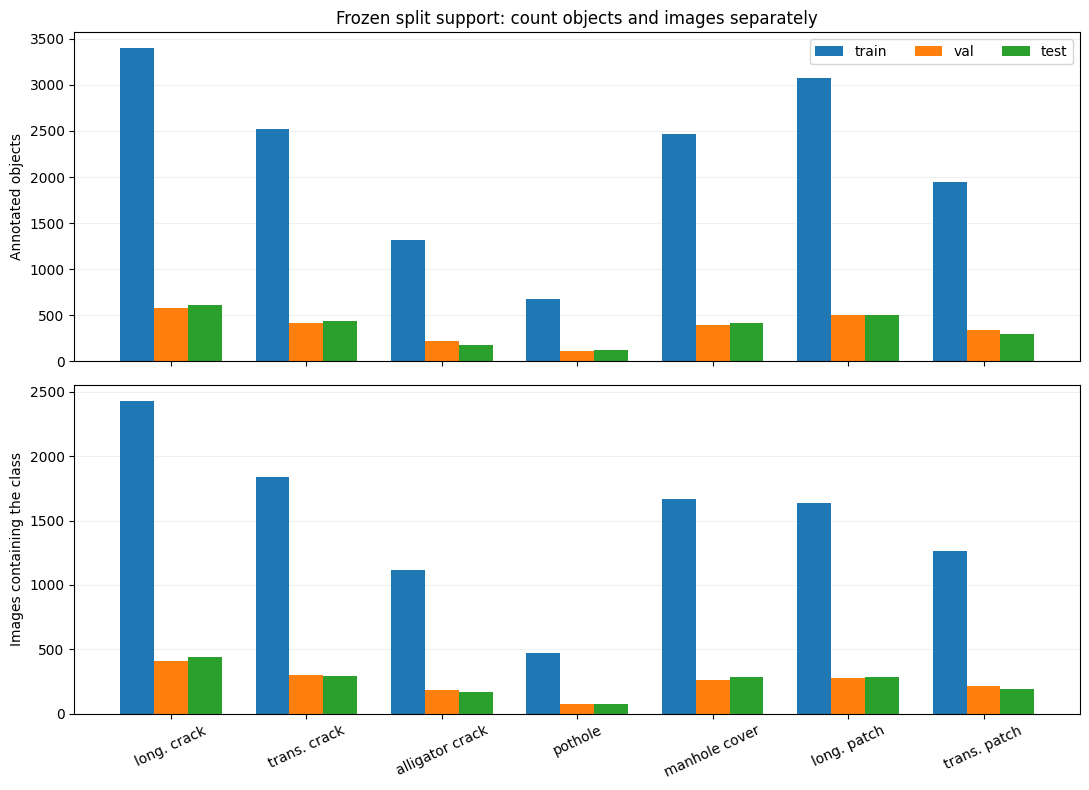

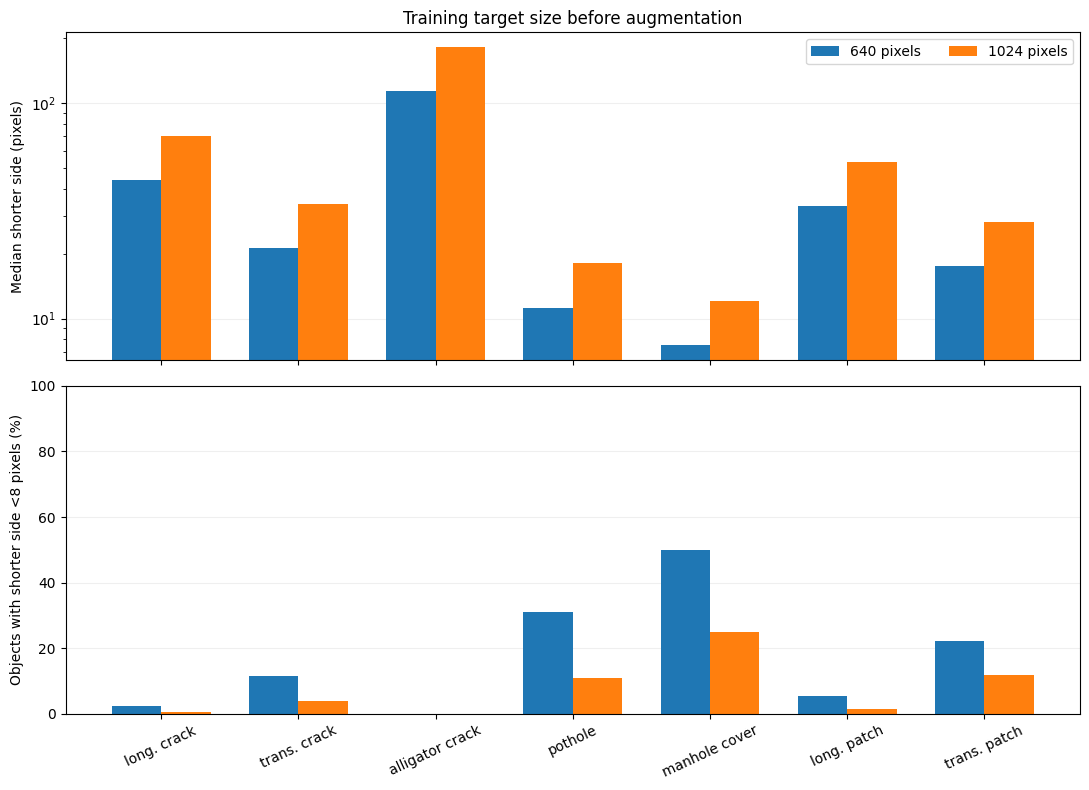

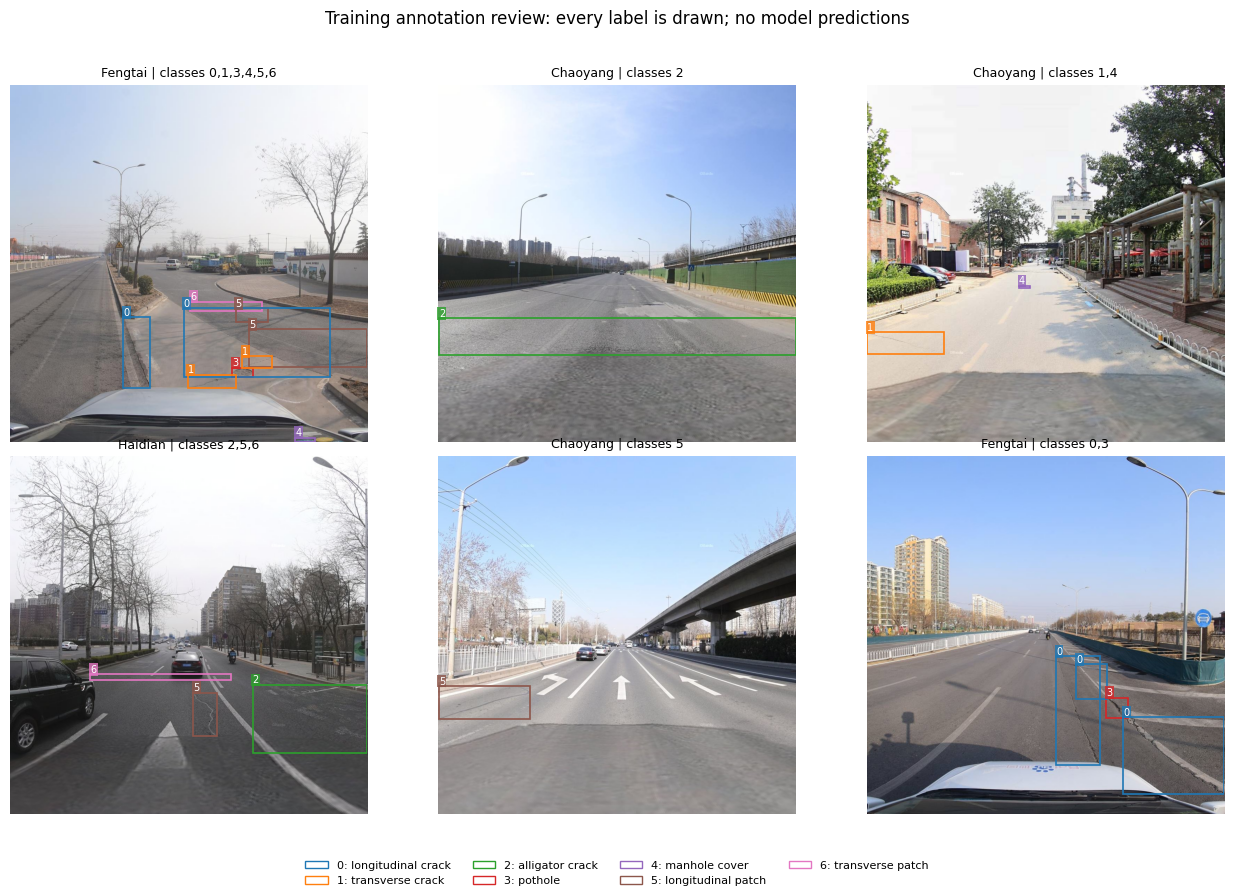

Diagnostics saved: /kaggle/working/road_models_v2/data_diagnostics
Frozen splits: {'train': {'images': 5918, 'objects': 15398, 'negative_images': 0}, 'val': {'images': 973, 'objects': 2556, 'negative_images': 0}, 'test': {'images': 1000, 'objects': 2572, 'negative_images': 0}}
Annotation flags for review: {'exact_duplicate_row': 1, 'same_class_high_overlap': 1}
All evaluated images have annotations. A separate clean-road evaluation is still needed.
Road/session independence remains unverified. No data or annotations were changed.


,split,class_id,class,images_with_class,objects
0,train,0,longitudinal crack,2431,3400
1,train,1,transverse crack,1838,2520
2,train,2,alligator crack,1113,1315
3,train,3,pothole,469,673
4,train,4,manhole cover,1664,2468
5,train,5,longitudinal patch,1632,3077
6,train,6,transverse patch,1264,1945
7,val,0,longitudinal crack,408,576
8,val,1,transverse crack,303,414
9,val,2,alligator crack,187,219


,class,resolution,objects,median_width_px,median_height_px,short_side_lt8_pct,area_lt32_squared_pct
14,longitudinal crack,640,3400,55.00,81.25,2.47,16.91
15,longitudinal crack,1024,3400,88.00,130.00,0.65,5.76
16,transverse crack,640,2520,171.25,21.25,11.51,18.49
17,transverse crack,1024,2520,274.00,34.00,4.05,4.40
18,alligator crack,640,1315,231.88,116.87,0.00,0.76
19,alligator crack,1024,1315,371.00,187.00,0.00,0.08
20,pothole,640,673,23.13,11.25,31.05,78.01
21,pothole,1024,673,37.00,18.00,11.00,58.84
22,manhole cover,640,2468,28.75,7.50,50.08,90.72
23,manhole cover,1024,2468,46.00,12.00,25.04,69.81


In [6]:
from matplotlib.patches import Rectangle
from IPython.display import display
import hashlib

diagnostic_dir = Path(OUTPUT) / 'data_diagnostics'
diagnostic_dir.mkdir(parents=True, exist_ok=True)
diagnostic_cfg = json.loads(Path(dataset_yaml).read_text())
diagnostic_root = Path(dataset_root).resolve()
support_rows, object_rows, image_rows, annotation_flags = [], [], [], []
split_summary, manifest_hashes, split_image_sets = {}, {}, {}
training_examples = []
flag_columns = ['split', 'image', 'kind', 'row_a', 'row_b', 'class_a', 'class_b', 'iou']

for split in ('train', 'val', 'test'):
    manifest = Path(diagnostic_cfg[split])
    if not manifest.is_absolute():
        manifest = diagnostic_root / manifest
    manifest_hashes[split] = hashlib.sha256(manifest.read_bytes()).hexdigest()
    images = [Path(line.strip()) for line in manifest.read_text().splitlines() if line.strip()]
    images = [(image if image.is_absolute() else diagnostic_root / image).resolve() for image in images]
    assert len(images) == len(set(images)), f'Duplicate paths inside {split} manifest'
    assert all(image.is_relative_to(diagnostic_root) and image.is_file() for image in images)
    split_image_sets[split] = set(images)
    object_counts = np.zeros(len(NAMES), dtype=np.int64)
    image_counts = np.zeros(len(NAMES), dtype=np.int64)
    negatives = 0
    for image in images:
        relative = image.relative_to(diagnostic_root)
        label_parts = list(relative.parts)
        assert label_parts.count('images') == 1, f'Unexpected image path: {relative}'
        label_parts[label_parts.index('images')] = 'labels'
        diagnostic_label_path = (diagnostic_root / Path(*label_parts)).with_suffix('.txt')
        assert diagnostic_label_path.is_file(), f'Missing label: {diagnostic_label_path}'
        with Image.open(image) as source_image:
            width, height = source_image.size
        assert width > 0 and height > 0
        parsed, source_line_numbers, seen_rows = [], [], {}
        for line_number, line in enumerate(diagnostic_label_path.read_text(encoding='utf-8-sig').splitlines(), start=1):
            if not line.strip():
                continue
            values = np.asarray([float(value) for value in line.split()], dtype=np.float64)
            assert values.shape == (5,) and np.isfinite(values).all(), f'Invalid row: {diagnostic_label_path}:{line_number}'
            class_number, center_x, center_y, box_w, box_h = values
            assert class_number.is_integer() and 0 <= class_number < len(NAMES)
            assert box_w > 0 and box_h > 0
            corners = np.asarray([center_x-box_w/2, center_y-box_h/2, center_x+box_w/2, center_y+box_h/2])
            assert corners.min() >= -1e-6 and corners.max() <= 1+1e-6, f'Out-of-image box: {diagnostic_label_path}:{line_number}'
            class_id = int(class_number)
            row_key = tuple(values.tolist())
            if row_key in seen_rows:
                annotation_flags.append(dict(split=split, image=str(relative), kind='exact_duplicate_row',
                    row_a=seen_rows[row_key], row_b=line_number, class_a=class_id, class_b=class_id, iou=1.0))
            else:
                seen_rows[row_key] = line_number
            parsed.append(values)
            source_line_numbers.append(line_number)
            object_counts[class_id] += 1
            object_rows.append(dict(split=split, image=str(relative), class_id=class_id, **{'class': NAMES[class_id]},
                center_x=center_x, center_y=center_y, width_norm=box_w, height_norm=box_h,
                source_width=width, source_height=height))
        boxes = np.asarray(parsed, dtype=np.float64).reshape(-1, 5)
        class_ids = set(boxes[:, 0].astype(int).tolist())
        if not len(boxes):
            negatives += 1
        for class_id in class_ids:
            image_counts[class_id] += 1
        if len(boxes) > 1:
            # Geometry flags are candidates for review, not instructions to delete boxes.
            xy1 = boxes[:, 1:3] - boxes[:, 3:5]/2
            xy2 = boxes[:, 1:3] + boxes[:, 3:5]/2
            areas = boxes[:, 3] * boxes[:, 4]
            for first in range(len(boxes)-1):
                intersection = np.maximum(0, np.minimum(xy2[first], xy2[first+1:]) - np.maximum(xy1[first], xy1[first+1:])).prod(axis=1)
                overlaps = intersection / np.maximum(areas[first] + areas[first+1:] - intersection, np.finfo(float).eps)
                for offset, overlap in enumerate(overlaps, start=first+1):
                    same_class = boxes[first, 0] == boxes[offset, 0]
                    threshold = 0.95 if same_class else 0.85
                    if overlap >= threshold:
                        annotation_flags.append(dict(split=split, image=str(relative),
                            kind='same_class_high_overlap' if same_class else 'different_class_high_overlap',
                            row_a=source_line_numbers[first], row_b=source_line_numbers[offset],
                            class_a=int(boxes[first, 0]), class_b=int(boxes[offset, 0]), iou=float(overlap)))
        image_rows.append(dict(split=split, image=str(relative), district=relative.parts[0],
            width=width, height=height, objects=len(boxes), negative=not len(boxes)))
        if split == 'train':
            resize_scale = 640 / max(width, height)
            short_sides = np.minimum(boxes[:, 3]*width, boxes[:, 4]*height)*resize_scale
            training_examples.append(dict(image=image, relative=str(relative), boxes=boxes, classes=class_ids,
                tiny=bool(np.any(short_sides < 8)), pothole_tiny=bool(np.any((boxes[:, 0] == 3) & (short_sides < 16)))))
    assert (object_counts > 0).all() and (image_counts > 0).all(), f'A class has no {split} support'
    split_summary[split] = dict(images=len(images), objects=int(object_counts.sum()), negative_images=negatives)
    for class_id, class_name in enumerate(NAMES):
        support_rows.append(dict(split=split, class_id=class_id, **{'class': class_name},
            images_with_class=int(image_counts[class_id]), objects=int(object_counts[class_id])))

assert all(split_image_sets[first].isdisjoint(split_image_sets[second])
    for first, second in [('train', 'val'), ('train', 'test'), ('val', 'test')]), 'Paths cross frozen split boundaries'
class_support = pd.DataFrame(support_rows)
box_geometry = pd.DataFrame(object_rows)
image_inventory = pd.DataFrame(image_rows)
flags = pd.DataFrame(annotation_flags, columns=flag_columns)
size_rows = []
for (split, class_id), group in box_geometry.groupby(['split', 'class_id'], sort=True):
    for resolution in (640, 1024):
        scale = resolution / np.maximum(group.source_width.to_numpy(), group.source_height.to_numpy())
        projected_w = group.width_norm.to_numpy()*group.source_width.to_numpy()*scale
        projected_h = group.height_norm.to_numpy()*group.source_height.to_numpy()*scale
        short_side = np.minimum(projected_w, projected_h)
        size_rows.append(dict(split=split, class_id=int(class_id), **{'class': NAMES[int(class_id)]}, resolution=resolution,
            objects=len(group), median_width_px=float(np.median(projected_w)), median_height_px=float(np.median(projected_h)),
            median_short_side_px=float(np.median(short_side)), p10_short_side_px=float(np.quantile(short_side, 0.10)),
            p90_short_side_px=float(np.quantile(short_side, 0.90)), short_side_lt8_pct=float(100*np.mean(short_side < 8)),
            short_side_lt16_pct=float(100*np.mean(short_side < 16)), area_lt32_squared_pct=float(100*np.mean(projected_w*projected_h < 32**2))))
box_sizes = pd.DataFrame(size_rows)
for table_name, table in [('class_support', class_support), ('box_sizes', box_sizes), ('box_geometry', box_geometry),
                          ('image_inventory', image_inventory), ('annotation_flags', flags)]:
    table.to_csv(diagnostic_dir/f'{table_name}.csv', index=False)

short_names = [name.replace('longitudinal', 'long.').replace('transverse', 'trans.') for name in NAMES]
positions = np.arange(len(NAMES)); bar_width = 0.25
figure, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for index, split in enumerate(('train', 'val', 'test')):
    selected_support = class_support[class_support.split == split].sort_values('class_id')
    axes[0].bar(positions+(index-1)*bar_width, selected_support.objects, bar_width, label=split)
    axes[1].bar(positions+(index-1)*bar_width, selected_support.images_with_class, bar_width, label=split)
axes[0].set(title='Frozen split support: count objects and images separately', ylabel='Annotated objects')
axes[1].set(ylabel='Images containing the class', xticks=positions, xticklabels=short_names)
axes[0].legend(ncol=3); axes[1].tick_params(axis='x', rotation=25)
for axis in axes:
    axis.grid(axis='y', alpha=0.2); axis.set_axisbelow(True)
figure.tight_layout(); figure.savefig(diagnostic_dir/'class_support.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close(figure)

figure, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for index, resolution in enumerate((640, 1024)):
    selected_sizes = box_sizes[(box_sizes.split == 'train') & (box_sizes.resolution == resolution)].sort_values('class_id')
    axes[0].bar(positions+(index-0.5)*0.36, selected_sizes.median_short_side_px, 0.36, label=f'{resolution} pixels')
    axes[1].bar(positions+(index-0.5)*0.36, selected_sizes.short_side_lt8_pct, 0.36, label=f'{resolution} pixels')
axes[0].set(title='Training target size before augmentation', ylabel='Median shorter side (pixels)')
axes[0].set_yscale('log'); axes[0].legend(ncol=2)
axes[1].set(ylabel='Objects with shorter side <8 pixels (%)', xticks=positions, xticklabels=short_names, ylim=(0, 100))
axes[1].tick_params(axis='x', rotation=25)
for axis in axes:
    axis.grid(axis='y', alpha=0.2); axis.set_axisbelow(True)
figure.tight_layout(); figure.savefig(diagnostic_dir/'object_sizes.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close(figure)

# Seeded tie breaking; prioritize class coverage and rare/tiny potholes, then fill to six images.
preview_order = np.random.default_rng(SEED).permutation(len(training_examples)).tolist()
preview_indices, uncovered, has_tiny, has_pothole_tiny = [], set(range(len(NAMES))), False, False
train_counts = class_support[class_support.split == 'train'].sort_values('class_id').objects.to_numpy()
while len(preview_indices) < min(6, len(preview_order)):
    available = [index for index in preview_order if index not in preview_indices]
    if not uncovered and has_tiny and has_pothole_tiny:
        preview_indices.extend(available[:6-len(preview_indices)])
        break
    def preview_score(index):
        example = training_examples[index]; new_classes = example['classes'] & uncovered
        return (len(new_classes) + int(example['tiny'] and not has_tiny) + int(example['pothole_tiny'] and not has_pothole_tiny),
            sum(1/float(train_counts[class_id]) for class_id in new_classes), -len(example['boxes']))
    chosen = max(available, key=preview_score)
    preview_indices.append(chosen); example = training_examples[chosen]
    uncovered -= example['classes']; has_tiny |= example['tiny']; has_pothole_tiny |= example['pothole_tiny']
preview_manifest = [dict(image=training_examples[index]['relative'], classes=sorted(training_examples[index]['classes']),
    annotations=len(training_examples[index]['boxes'])) for index in preview_indices]
(diagnostic_dir/'preview_manifest.json').write_text(json.dumps(preview_manifest, indent=2))
figure, axes = plt.subplots(2, 3, figsize=(13, 9))
palette = plt.get_cmap('tab10')
for axis, index in zip(axes.flat, preview_indices):
    example = training_examples[index]
    with Image.open(example['image']) as source_image:
        preview_image = source_image.convert('RGB')
        width, height = preview_image.size
        axis.imshow(preview_image)
    for class_number, center_x, center_y, box_w, box_h in example['boxes']:
        class_id = int(class_number); left=(center_x-box_w/2)*width; top=(center_y-box_h/2)*height
        axis.add_patch(Rectangle((left, top), box_w*width, box_h*height, fill=False, edgecolor=palette(class_id), linewidth=1.2))
        axis.text(left, top, str(class_id), color='white', fontsize=7, va='bottom',
            bbox=dict(facecolor=palette(class_id), edgecolor='none', alpha=0.8, pad=1))
    axis.set_title(f"{example['relative'].split('/')[0].split(chr(92))[0]} | classes {','.join(map(str, sorted(example['classes'])))}", fontsize=9)
    axis.axis('off')
for axis in list(axes.flat)[len(preview_indices):]:
    axis.axis('off')
legend_handles = [Rectangle((0, 0), 1, 1, fill=False, edgecolor=palette(index), label=f'{index}: {name}') for index, name in enumerate(NAMES)]
figure.suptitle('Training annotation review: every label is drawn; no model predictions', fontsize=12)
figure.legend(handles=legend_handles, loc='lower center', ncol=4, fontsize=8, frameon=False)
figure.tight_layout(rect=(0, 0.07, 1, 0.96))
figure.savefig(diagnostic_dir/'training_annotation_preview.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close(figure)

diagnostic_summary = dict(split_counts=split_summary, source_records=len(records), excluded_images=len(excluded),
    manifest_sha256=manifest_hashes, dimensions=image_inventory.groupby(['width', 'height']).size().reset_index(name='images').to_dict('records'),
    annotation_flag_counts=flags.kind.value_counts().to_dict(), preview_images=preview_manifest,
    preview_uncovered_class_ids=sorted(uncovered), preview_has_short_side_lt8_at640=bool(has_tiny),
    preview_has_pothole_short_side_lt16_at640=bool(has_pothole_tiny),
    overlap_policy='review candidates only; retain every original annotation',
    negative_scene_limit='No clean-road benchmark is established; background within positive images still contributes training signal.',
    group_independence='Unverified by road/location/capture session; dHash screening and district names do not establish independence.',
    size_definition='Normalized annotation geometry projected by resolution/max(source width, source height), before augmentation; square resize/letterbox geometry, independent of any augmented training view.')
(diagnostic_dir/'summary.json').write_text(json.dumps(diagnostic_summary, indent=2))
print('Diagnostics saved:', diagnostic_dir)
print('Frozen splits:', split_summary)
print('Annotation flags for review:', diagnostic_summary['annotation_flag_counts'])
if all(values['negative_images'] == 0 for values in split_summary.values()):
    print('All evaluated images have annotations. A separate clean-road evaluation is still needed.')
print('Road/session independence remains unverified. No data or annotations were changed.')
display(class_support)
display(box_sizes[(box_sizes.split == 'train')][['class', 'resolution', 'objects', 'median_width_px', 'median_height_px', 'short_side_lt8_pct', 'area_lt32_squared_pct']].round(2))


## 5. Experiment matrix: three primary runs enabled

| ID | Model | Epoch cap | Train pixels | Class power | Question |
|---|---|---:|---:|---:|---|
| control_640 | YOLO26n | 30 | 640 | 0 | Does the new training plan improve the nano reference? |
| control_1024 | YOLO26n | 30 | 1024 | 0 | What changes when training resolution increases? |
| v8_small | YOLOv8s | 30 | 1024 | 0 | Small established-family candidate |
| v11_small | YOLO11s | 30 | 1024 | 0 | Small newer-family candidate |
| v26_medium | YOLO26m | 30 | 1024 | 0 | Medium-capacity challenger; compare with YOLO26n |
| weighting | Best new 1024 configuration, selected on validation | 30 | 1024 | 0.5 | Does damped frequency weighting help this same configuration? |

YOLOv8s versus YOLO11s compares families at the same named tier. YOLO26m versus
YOLO26n examines capacity within one family. The mixed s/s/m leaderboard compares
deployable candidates; it cannot establish family superiority at equal compute.

**Deadline configuration:** only `v8_small`, `v11_small`, and `v26_medium` are enabled. The two nano controls and weighting trial are optional and disabled. No controlled resolution/weighting effect will be claimed unless those optional experiments actually run.

All new trials use global batch 8 and nominal batch 64 (gradient accumulation),
the same seed, optimizer, augmentation and split. Compared with v1, microbatch
and schedule also change, so v1 versus v2 is an upgraded-recipe comparison.
Every candidate is evaluated at a common 1024 pixels. The 640 control also gets
a native-640 validation result, making the train/inference-resolution distinction visible.

Thirty epochs is a cap, not an assurance of convergence. A still-rising curve is
reported as such. We preserve the baseline AdamW learning rate and augmentation
recipe while testing the requested changes; class weighting is the isolated
hyperparameter trial. No exhaustive search or guaranteed global optimum is claimed.

In [7]:
COMMON = dict(data=str(dataset_yaml), epochs=30, batch=GLOBAL_BATCH, nbs=64, device=[0,1],
    seed=SEED, workers=4, cache=False, amp=True, optimizer='AdamW', lr0=0.001,
    lrf=0.01, momentum=0.937, weight_decay=0.0005, warmup_epochs=3.0, cos_lr=False,
    patience=10, close_mosaic=10, mosaic=1.0, scale=0.5, mixup=0.0,
    degrees=0.0, flipud=0.0, fliplr=0.5, cls_pw=0.0, deterministic=True,
    save=True, save_period=1, plots=True, exist_ok=True, verbose=False, nms=True)
assert GLOBAL_BATCH >= 2 and GLOBAL_BATCH % 2 == 0
TRIALS = {}
if RUN_CONTROLS:
    TRIALS.update(control_640=dict(model='yolo26n', imgsz=640),
                  control_1024=dict(model='yolo26n', imgsz=1024))
TRIALS.update(v8_small=dict(model='yolov8s', imgsz=1024),
              v11_small=dict(model='yolo11s', imgsz=1024),
              v26_medium=dict(model='yolo26m', imgsz=1024))
TRIALS = {key: {**COMMON, **spec} for key, spec in TRIALS.items()}
UNWEIGHTED_TRIALS = dict(TRIALS)

def trial_dir(key, spec):
    return OUTPUT/'runs'/(key + '-' + digest({'settings':spec, 'data':DATA_ID,
        'runtime':ENVIRONMENT['packages'], 'worker_sha256':hashlib.sha256(WORKER_SOURCE.encode()).hexdigest()})[:12])

display(pd.DataFrame([{'trial':key, 'model':spec['model'], 'epochs':spec['epochs'],
    'train_imgsz':spec['imgsz'], 'batch':spec['batch'], 'cls_pw':spec['cls_pw']} for key,spec in TRIALS.items()]))


,trial,model,epochs,train_imgsz,batch,cls_pw
0,v8_small,yolov8s,30,1024,8,0.0
1,v11_small,yolo11s,30,1024,8,0.0
2,v26_medium,yolo26m,30,1024,8,0.0


## 6. Training worker: immutable settings, real resumable checkpoints

Each configuration has a separate directory and fingerprint. Completion is reused
only when data, environment, settings and pretrained-file identity match.
Intermediate optimizer checkpoints are preserved before inference stripping.
OOM/time limits never silently lower resolution or count an interrupted run as
a completed 30-epoch experiment. If batch 8 does not fit, use a new experiment
root and one smaller common batch for every candidate, then rerun the pilot.

In [8]:
WORKER_SOURCE = "\nfrom pathlib import Path\nimport os, sys, json, shutil, numpy as np, pandas as pd, torch\nfrom ultralytics import YOLO\nfrom ultralytics.utils.torch_utils import unwrap_model, strip_optimizer\npayload = json.loads(Path(sys.argv[1]).read_text())\ncfg = payload['train']; rank = int(os.environ.get('RANK', '-1'))\nrun = Path(cfg['project']) / cfg['name']; resume = run/'weights/last-resumable.pt'\nrecovery_only = len(sys.argv) > 2 and sys.argv[2] == '--recover-only'\n\ndef save_json(path, value):\n    temporary = path.with_name(path.name + '.tmp')\n    temporary.write_text(json.dumps(value, indent=2)); os.replace(temporary, path)\n\ndef preserve(trainer):\n    if rank in (-1, 0) and trainer.last.exists():\n        temporary = resume.with_suffix('.tmp')\n        shutil.copy2(trainer.last, temporary); os.replace(temporary, resume)\n\ndef verify_weights(trainer):\n    actual_counts = trainer.get_class_counts()\n    assert np.all(actual_counts > 0)\n    expected = actual_counts ** (-float(trainer.args.cls_pw)); expected /= expected.mean()\n    if trainer.args.cls_pw:\n        actual = unwrap_model(trainer.model).class_weights.detach().cpu().numpy()\n        assert np.allclose(actual, expected, rtol=1e-5, atol=1e-6), 'Class weighting differs from pinned API.'\n    if rank in (-1, 0):\n        save_json(run/'class_weights.json', {'counts':actual_counts.tolist(),\n            'weights':expected.tolist(), 'cls_pw':trainer.args.cls_pw})\n\nif resume.exists():\n    saved = torch.load(resume, map_location='cpu', weights_only=False)\n    assert saved.get('optimizer') is not None, 'Use the generated resumable checkpoint, not stripped best.pt.'\n    # A crash after the final epoch may leave a complete optimizer checkpoint but no status file.\n    done_epochs = int(saved.get('epoch', -1)) + 1\n    del saved\nelse: done_epochs = 0\nif recovery_only: assert done_epochs >= cfg['epochs'], 'Checkpoint is not finished; recovery cannot train.'\nif done_epochs < cfg['epochs']:\n    model = YOLO(str(resume) if resume.exists() else payload['pretrained'])\n    model.add_callback('on_model_save', preserve)\n    model.add_callback('on_pretrain_routine_end', verify_weights)\n    model.train(**cfg, resume=str(resume) if resume.exists() else False)\n    assert int(model.trainer.args.batch) == cfg['batch'], 'Trainer altered batch size; new controlled run required.'\nelif rank in (-1, 0):\n    assert (run/'weights/best.pt').is_file()\n    strip_optimizer(run/'weights/best.pt')\nif rank in (-1, 0):\n    history = pd.read_csv(run/'results.csv'); history.columns = history.columns.str.strip()\n    loss_cols = [x for x in history if 'loss' in x and x.startswith(('train/', 'val/'))]\n    assert len(history) > 0 and loss_cols and np.isfinite(history[loss_cols].to_numpy()).all()\n    assert (run/'weights/best.pt').is_file()\n    epochs = len(history)\n    assert 0 < epochs <= cfg['epochs']\n    import hashlib\n    best_sha = hashlib.sha256((run/'weights/best.pt').read_bytes()).hexdigest()\n    save_json(run/'complete.json', {'status':'recovered_completed' if recovery_only else\n        ('completed_cap' if epochs == cfg['epochs'] else 'early_stopped'),\n        'actual_epochs':epochs, 'planned_epochs':cfg['epochs'], 'losses_finite':True,\n        'checkpoint_sha256':best_sha})\n"
WORKER_PATH = OUTPUT/'train_worker_v2.py'
WORKER_PATH.write_text(WORKER_SOURCE)

def total_training_spent():
    return sum(json.loads(line)['seconds'] for path in (OUTPUT/'runs').glob('*/timing.jsonl')
               for line in path.read_text().splitlines() if line.strip())

def remaining_gpu_hours():
    if AVAILABLE_GPU_HOURS is None: return None
    assert isinstance(AVAILABLE_GPU_HOURS, (int,float)) and AVAILABLE_GPU_HOURS > 0
    return AVAILABLE_GPU_HOURS - 2*(time.monotonic()-QUOTA_SESSION_START)/3600

def completed_status(run, spec):
    status=json.loads((run/'complete.json').read_text())
    history=pd.read_csv(run/'results.csv'); history.columns=history.columns.str.strip()
    assert status['losses_finite'] and status['actual_epochs']==len(history)>0
    assert status['planned_epochs']==spec['epochs'] and len(history)<=spec['epochs']
    cols=[c for c in history if 'loss' in c and c.startswith(('train/','val/'))]
    assert cols and np.isfinite(history[cols].to_numpy()).all()
    assert file_sha(run/'weights/best.pt')==status['checkpoint_sha256']
    return status

def run_trial(key, spec, pilot=False):
    run = trial_dir(key, spec)
    if not RUN_TRAINING:
        print(key, ': training switch is off;', 'saved result available' if (run/'complete.json').exists() else 'pending')
        return run
    run.mkdir(parents=True, exist_ok=True)
    base = OUTPUT/'pretrained'/f"{spec['model']}.pt"; base.parent.mkdir(exist_ok=True)
    if not base.exists():
        downloaded = YOLO(str(base)); del downloaded; gc.collect()
    cfg = {k:v for k,v in spec.items() if k != 'model'}
    cfg.update(project=str(run.parent), name=run.name)
    payload = {'train':cfg, 'pretrained':str(base), 'pretrained_sha256':file_sha(base),
        'dataset_id':DATA_ID, 'environment':ENVIRONMENT['packages'], 'worker_sha256':file_sha(WORKER_PATH)}
    payload_path = run/'training_spec.json'; immutable_json(payload_path, payload)
    if (run/'complete.json').exists():
        completed_status(run,spec)
        print(key, ': verified existing completion'); return run
    assert not (OUTPUT/'frozen_test_plan.json').exists(), 'Test plan frozen: start a separate output root for further training.'
    spent = sum(json.loads(x)['seconds'] for x in (run/'timing.jsonl').read_text().splitlines()) if (run/'timing.jsonl').exists() else 0
    finished_history = False
    if (run/'results.csv').is_file() and (run/'weights/last-resumable.pt').is_file():
        finished_history = len(pd.read_csv(run/'results.csv')) == spec['epochs']
    remaining = min((1200 if pilot else MAX_SECONDS_PER_RUN)-spent,
                    MAX_TOTAL_TRAIN_SECONDS-total_training_spent())
    if AVAILABLE_GPU_HOURS is not None:
        remaining = min(remaining, max(0,remaining_gpu_hours()-1.0)*1800)
    if finished_history: remaining = 180  # Metadata recovery only: no further training is allowed.
    assert remaining > 0, 'Training budget exhausted; keep checkpoints and revise the explicit budget.'
    command = [sys.executable, '-m', 'torch.distributed.run', '--standalone', '--nproc_per_node=2', str(WORKER_PATH), str(payload_path)]
    if finished_history: command.append('--recover-only')
    print(f"START TRAINING: {key} | {spec['model']} | {spec['imgsz']}px | max {spec['epochs']} epochs | global batch {spec['batch']}", flush=True)
    started = time.monotonic(); process = subprocess.Popen(command, start_new_session=True)
    try:
        returncode = process.wait(timeout=remaining)
        assert returncode == 0, f'{key} failed. Inspect OOM/runtime logs; no settings were silently changed.'
        assert (run/'complete.json').is_file()
    except (subprocess.TimeoutExpired, KeyboardInterrupt):
        if process.poll() is None: os.killpg(process.pid, signal.SIGTERM)
        try: process.wait(timeout=20)
        except subprocess.TimeoutExpired:
            os.killpg(process.pid, signal.SIGKILL); process.wait()
        raise RuntimeError(f'{key} interrupted. Same configuration can resume from its last saved epoch.')
    finally:
        with (run/'timing.jsonl').open('a') as stream:
            stream.write(json.dumps({'seconds':time.monotonic()-started, 'exit_code':process.returncode})+'\n')
    status = completed_status(run, spec)
    print(f"TRAINING FINISHED: {key} | actual epochs {status['actual_epochs']} | checkpoint {run/'weights/best.pt'}", flush=True)
    return run

def unfinished_epochs(key,spec):
    run=trial_dir(key,spec)
    if (run/'complete.json').exists():
        completed_status(run,spec); return 0
    epochs=len(pd.read_csv(run/'results.csv')) if (run/'results.csv').is_file() else 0
    return max(0,spec['epochs']-epochs)

### Recover the completed models

Register the three uploaded checkpoints with their saved 30-epoch histories and import provenance. In fresh mode, reuse completed matching runs and train missing models.


In [9]:
# Recovery helper: this cell runs after the training-engine definitions.
# Attach all three downloaded best.pt files as Kaggle input, or put them anywhere
# below /kaggle/working. Folder names do not matter for audited downloads.
AUDITED_DOWNLOADS = {
    'v8_small': (22603562, '5a5b96a5204dffb8371ea621b6461bc3939ec0b11fc9f6ebfbc3af38d684a3ba'),
    'v11_small': (19262042, 'aed9032517943b4a5ffe30a01a74c974bc8e7e625b6b7a6e6ede1f688e1a6c63'),
    'v26_medium': (44120153, 'fab0e117d8871eeea47a45a98e33963a524b7751bae793c796258bf1a457c0c4'),
}


def register_finished_download(key, source):
    spec = TRIALS[key]
    run = trial_dir(key, spec)
    source = Path(source)
    checkpoint = torch.load(source, map_location='cpu', weights_only=False)
    model = checkpoint.get('ema')
    if model is None:
        model = checkpoint.get('model')
    args = checkpoint.get('train_args', {})
    assert model is not None and list(model.names.values()) == NAMES, 'Wrong class map.'
    assert Path(str(args.get('model', ''))).stem == spec['model'], 'Wrong model architecture.'
    for field in ['epochs', 'imgsz', 'batch', 'seed', 'cls_pw']:
        assert args.get(field) == spec[field], f'{key}: saved {field} differs from this experiment.'
    history = pd.DataFrame(checkpoint.get('train_results') or {})
    history.columns = history.columns.str.strip()
    assert 'epoch' in history and history.epoch.tolist() == list(range(1, spec['epochs']+1)), (
        f'{key}: best.pt is not evidence of a completed {spec["epochs"]}-epoch run. '
        'Keep its resumable checkpoint; do not mark partial training complete.')
    losses = [c for c in history if 'loss' in c and c.startswith(('train/', 'val/'))]
    assert losses and np.isfinite(history[losses].to_numpy()).all(), 'Invalid training losses.'
    assert 'metrics/mAP50-95(B)' in history and np.isfinite(history['metrics/mAP50-95(B)']).all()
    checksum = file_sha(source)
    if key in AUDITED_DOWNLOADS:
        assert checksum == AUDITED_DOWNLOADS[key][1], 'This is not the audited downloaded model.'
    assert not (OUTPUT/'frozen_test_plan.json').exists(), 'Do not alter an already frozen test plan.'
    run.mkdir(parents=True, exist_ok=True)
    weights = run/'weights'; weights.mkdir(exist_ok=True)
    destination = weights/'best.pt'
    if source.resolve() != destination.resolve():
        if destination.exists():
            assert file_sha(destination) == checksum, 'Different best.pt already occupies this run.'
        else:
            temporary = weights/'best.importing.pt'
            shutil.copy2(source, temporary)
            assert file_sha(temporary) == checksum
            os.replace(temporary, destination)
    history.to_csv(run/'results.csv', index=False)
    original_seconds = float(history['time'].iloc[-1]) if 'time' in history else None
    assert original_seconds is None or (math.isfinite(original_seconds) and original_seconds >= 0)
    atomic_json(run/'training_spec.json', {
        'train': args, 'imported': True, 'source': str(source),
        'checkpoint_sha256': checksum, 'checkpoint_ultralytics': checkpoint.get('version'),
        'current_evaluation_data_id': DATA_ID,
        'provenance_note': 'Recovered checkpoint metadata. Original data hash/environment file was not embedded; current environment describes evaluation.'})
    atomic_json(run/'class_weights.json', {
        'cls_pw': args['cls_pw'], 'weights': [1.0]*len(NAMES), 'counts': None,
        'note': 'Unweighted training; exact post-deduplication trainer counts were not embedded.'})
    (run/'timing.jsonl').write_text(json.dumps({
        'seconds': 0.0, 'original_training_seconds': original_seconds,
        'imported': True, 'exit_code': None})+'\n')
    atomic_json(run/'complete.json', {
        'status': 'imported_completed', 'actual_epochs': len(history),
        'planned_epochs': spec['epochs'], 'losses_finite': True,
        'checkpoint_sha256': checksum, 'imported': True,
        'training_ultralytics': checkpoint.get('version')})
    del checkpoint, model
    gc.collect()
    completed_status(run, spec)
    print(f'SKIP TRAINING: {key} | verified {len(history)} epochs | {destination}', flush=True)
    return run


def find_audited_download(key):
    size, checksum = AUDITED_DOWNLOADS[key]
    for root in [Path('/kaggle/working'), Path('/kaggle/input')]:
        for path in root.rglob('*.pt'):
            if path.is_file() and path.stat().st_size == size and file_sha(path) == checksum:
                return path
    return None


def train_or_reuse(key):
    spec = TRIALS[key]
    run = trial_dir(key, spec)
    if (run/'complete.json').exists():
        completed_status(run, spec)
        print(f'SKIP TRAINING: {key} | verified existing completion', flush=True)
        return run
    if key in AUDITED_DOWNLOADS:
        source = find_audited_download(key)
        if source is not None:
            return register_finished_download(key, source)
        if REQUIRE_RECOVERED_MODELS:
            raise FileNotFoundError(
                f'{key}: attach your audited best.pt as Kaggle input or copy it below /kaggle/working. '
                'Training is blocked to prevent accidentally repeating the completed model.')
    best = run/'weights/best.pt'
    resumable = run/'weights/last-resumable.pt'
    if best.exists() and not resumable.exists():
        # A completed loose best.pt can be registered; partial best.pt must not silently count as done.
        return register_finished_download(key, best)
    if RUN_TRAINING:
        assert BUDGET_PASSED, 'Run the pilot/explicit pilot-bypass cell first.'
    print(f'{"RESUME" if resumable.exists() else "TRAIN"}: {key}', flush=True)
    return run_trial(key, spec)


# Resolve all three completed models before evaluation. Missing downloads
# stop here, rather than after spending GPU time on another model.
if REQUIRE_RECOVERED_MODELS:
    for key in AUDITED_DOWNLOADS:
        spec = TRIALS[key]
        run = trial_dir(key, spec)
        assert (run/'complete.json').exists() or find_audited_download(key) is not None, (
            f'Missing {spec["model"]}: attach its downloaded best.pt before Run All.')
print('Recovery helper ready: all three completed models are required.' if REQUIRE_RECOVERED_MODELS else 'Recovery helper ready: reuse completed runs and train missing models when enabled.')


def recorded_training_seconds(run):
    total = 0.0
    for line in (Path(run)/'timing.jsonl').read_text().splitlines():
        if line.strip():
            item = json.loads(line)
            original = item.get('original_training_seconds')
            total += float(original if original is not None else item['seconds'])
    return total


Recovery helper ready: all three completed models are required.


## 7. Optional pilot for recovery or fresh training

Recovery mode skips the pilot because all three models are already trained. Fresh mode runs the original two-epoch medium-model resource probe before training missing models.


In [10]:
if RUN_PILOT:
    pilot_spec = {**TRIALS['v26_medium'], 'epochs':2, 'patience':2, 'plots':False, 'close_mosaic':0}
    pilot_run = run_trial('pilot_26m_1024', pilot_spec, pilot=True)
    BUDGET_PASSED = False
    if RUN_TRAINING:
        pilot_history = pd.read_csv(pilot_run/'results.csv')
        assert len(pilot_history) == 2
        probe = YOLO(str(pilot_run/'weights/best.pt'))
        assert list(probe.names.values()) == NAMES
        assert len(probe.predict(str(split_paths('val')[0]), imgsz=1024, device=0,
            quantize=32, rect=False, nms=True, verbose=False)) == 1
        del probe; gc.collect(); torch.cuda.empty_cache()
        times = pilot_history['time'].to_numpy(float)
        epoch_seconds = max(float(times[-1]/2), float(times[-1]-times[-2]))
        planned_trials = len(UNWEIGHTED_TRIALS) + int(RUN_WEIGHTING_TRIAL)
        spent_hours = total_training_spent()/3600
        remaining_epochs = sum(unfinished_epochs(k,s) for k,s in UNWEIGHTED_TRIALS.items())
        # Until the unweighted winner is frozen, reserve one complete paired trial conservatively.
        weighting_plan_path = OUTPUT/'weighting_plan.json'
        if RUN_WEIGHTING_TRIAL:
            if weighting_plan_path.exists():
                wp=json.loads(weighting_plan_path.read_text())
                remaining_epochs += unfinished_epochs(wp['trial'],wp['settings'])
            else: remaining_epochs += 30
        required_wall_hours = epoch_seconds*remaining_epochs*1.35/3600
        required_gpu_hours = 2*required_wall_hours+2.0
        display(pd.DataFrame([{'pilot_epoch_seconds':epoch_seconds, 'planned_trials':planned_trials,
            'estimated_remaining_gpu_hours':required_gpu_hours, 'session_gpu_hours_remaining':remaining_gpu_hours()}]))
        if epoch_seconds*30*1.35 > MAX_SECONDS_PER_RUN:
            print('Estimate: a full 30-epoch medium run might exceed the per-run cap.')
        if spent_hours+required_wall_hours > MAX_TOTAL_TRAIN_SECONDS/3600:
            print('Estimate: all runs might exceed the total training cap.')
        if AVAILABLE_GPU_HOURS is not None and required_gpu_hours > remaining_gpu_hours():
            print('Estimate exceeds the manually entered GPU quota; Kaggle may interrupt the run.')
        atomic_json(OUTPUT/'budget.json', {'estimated_gpu_hours':required_gpu_hours,
            'declared_available_gpu_hours':AVAILABLE_GPU_HOURS, 'remaining_epochs':remaining_epochs, 'epoch_seconds_proxy':epoch_seconds,
            'planned_trials':planned_trials, 'two_gpu_multiplier':2})
        BUDGET_PASSED = True

else:
    BUDGET_PASSED = True  # Explicit recovery bypass; no resource estimate was performed.
    print("Pilot skipped: all three trained models are being recovered.")


Pilot skipped: all three trained models are being recovered.


## 8. Run the two controls and the three challengers

Each cell is independently resumable. Controls expose a cause; challengers seek
a better accuracy/cost trade-off. No v1 training or test evaluation runs here.

### YOLO26n, 30 epochs, 640 training pixels

The displayed status and saved history determine completion; the model name alone does not.

In [11]:
if 'control_640' in TRIALS:
    if RUN_TRAINING: assert BUDGET_PASSED, 'Complete the pilot and budget check first.'
    run_trial('control_640', TRIALS['control_640'])


### YOLO26n, 30 epochs, 1024 training pixels

The displayed status and saved history determine completion; the model name alone does not.

In [12]:
if 'control_1024' in TRIALS:
    if RUN_TRAINING: assert BUDGET_PASSED, 'Complete the pilot and budget check first.'
    run_trial('control_1024', TRIALS['control_1024'])


### YOLOv8s, 30 epochs, 1024 training pixels

The displayed status and saved history determine completion; the model name alone does not.

In [13]:
train_or_reuse('v8_small')


SKIP TRAINING: v8_small | verified 30 epochs | /kaggle/working/road_models_v2/runs/v8_small-0fc48fc6778d/weights/best.pt


PosixPath('/kaggle/working/road_models_v2/runs/v8_small-0fc48fc6778d')

### YOLO11s, 30 epochs, 1024 training pixels

The displayed status and saved history determine completion; the model name alone does not.

In [14]:
train_or_reuse('v11_small')


SKIP TRAINING: v11_small | verified 30 epochs | /kaggle/working/road_models_v2/runs/v11_small-1fc5f71b3238/weights/best.pt


PosixPath('/kaggle/working/road_models_v2/runs/v11_small-1fc5f71b3238')

### YOLO26m, 30 epochs, 1024 training pixels

The displayed status and saved history determine completion; the model name alone does not.

In [15]:
train_or_reuse('v26_medium')


SKIP TRAINING: v26_medium | verified 30 epochs | /kaggle/working/road_models_v2/runs/v26_medium-c744911c4621/weights/best.pt


PosixPath('/kaggle/working/road_models_v2/runs/v26_medium-c744911c4621')

## 9. One evaluation contract for every candidate

Validation comparison uses **1024 / batch 1 / FP32 / square padding / NMS**,
confidence floor 0.001, NMS IoU 0.7 and maximum 300 detections. Every row states
both training and inference resolution. Legacy models are reevaluated only if
their actual weights are attached; historical scores are never substituted.
Official AP and fixed-confidence one-to-one counts answer different questions.

In [16]:
MAP_CONF, FIXED_CONF, NMS_IOU, MAX_DET = 0.001, 0.25, 0.7, 300
EVAL_SIZE = 1024
def ground_truth(image):
    parts = list(image.parts); low = [x.lower() for x in parts]
    if 'images' not in low: raise ValueError(f'No images/ component: {image}')
    parts[len(low)-1-low[::-1].index('images')] = 'labels'
    label = Path(*parts).with_suffix('.txt')
    if not label.is_file(): raise FileNotFoundError(label)
    with Image.open(image) as im: width, height = im.size
    rows = []
    for line in label.read_text().splitlines():
        if line.strip():
            c,cx,cy,w,h = map(float,line.split())
            rows.append([int(c),(cx-w/2)*width,(cy-h/2)*height,
                         (cx+w/2)*width,(cy+h/2)*height])
    return np.asarray(rows,dtype=float).reshape(-1,5)

def match_boxes(gt, pred, return_indices=False):
    counts = np.zeros((len(NAMES),3),dtype=int); used=set(); matched=[]
    for k in np.argsort(-pred[:,1],kind='stable') if len(pred) else []:
        cls=int(pred[k,0]); ids=np.array([j for j in range(len(gt))
                            if j not in used and int(gt[j,0])==cls],dtype=int)
        if len(ids):
            b=pred[k,2:6]; g=gt[ids,1:5]
            wh=np.maximum(0,np.minimum(g[:,2:],b[2:])-np.maximum(g[:,:2],b[:2]))
            inter=wh[:,0]*wh[:,1]; ag=(g[:,2]-g[:,0])*(g[:,3]-g[:,1])
            ab=(b[2]-b[0])*(b[3]-b[1]); union=ag+ab-inter
            ious=np.divide(inter,union,out=np.zeros_like(inter),where=union>0)
            j=int(np.argmax(ious))
            if ious[j]>=.5: used.add(int(ids[j])); counts[cls,0]+=1; matched.append(float(ious[j])); continue
        counts[cls,1]+=1
    for j,cls in enumerate(gt[:,0].astype(int)):
        if j not in used: counts[cls,2]+=1
    return (counts,matched,sorted(used)) if return_indices else (counts,matched)


def prediction(model, image, size=EVAL_SIZE):
    result = model.predict(str(image), imgsz=size, device=0, batch=1, quantize=32,
        rect=False, conf=MAP_CONF, iou=NMS_IOU, max_det=MAX_DET, nms=True,
        verbose=False, save=False)[0]
    boxes = result.boxes.data.detach().cpu().numpy() if result.boxes is not None else np.empty((0,6))
    return np.column_stack((boxes[:,5], boxes[:,4], boxes[:,:4])).astype(np.float32) if len(boxes) else np.empty((0,6),np.float32)

def candidate(key, spec, run):
    ck = run/'weights/best.pt'; status = completed_status(run,spec)
    return {'trial':key, 'model':spec['model'], 'train_imgsz':spec['imgsz'],
        'planned_epochs':spec['epochs'], 'actual_epochs':status['actual_epochs'],
        'cls_pw':spec['cls_pw'], 'checkpoint':str(ck), 'checkpoint_sha256':file_sha(ck),
        'run':str(run), 'origin':'round2', 'status':status['status']}

def new_candidates():
    return {key:candidate(key,spec,trial_dir(key,spec)) for key,spec in TRIALS.items()
        if (trial_dir(key,spec)/'complete.json').is_file()}

def legacy_candidates(input_root=Path('/kaggle/input')):
    """Identify round-one checkpoints from saved metadata, regardless of folder labels."""
    expected_models = ['yolov8n', 'yolo11n', 'yolo26n']
    automatic = sorted(set(p for p in Path(input_root).rglob('*.pt')
                           if p.name == 'best.pt' or p.name in {f'{m}-best.pt' for m in expected_models}))
    explicit_paths = {name: Path(path) for name, path in LEGACY_WEIGHTS.items() if path}
    summaries = {}
    for path in sorted(set(automatic) | set(explicit_paths.values())):
        try:
            checkpoint = torch.load(path, map_location='cpu', weights_only=False)
            model = checkpoint.get('ema')
            if model is None:
                model = checkpoint.get('model')
            args = checkpoint.get('train_args', {})
            history = checkpoint.get('train_results') or {}
            names = getattr(model, 'names', {})
            names = list(names.values()) if isinstance(names, dict) else list(names)
            summaries[path] = {
                'model': Path(str(args.get('model', ''))).stem,
                'epochs': args.get('epochs'), 'imgsz': args.get('imgsz'),
                'seed': args.get('seed'), 'names': names,
                'history_epochs': len(history.get('epoch', [])),
            }
            del checkpoint, model
        except Exception as error:
            if path in explicit_paths.values():
                raise RuntimeError(f'Cannot inspect explicit legacy checkpoint: {path}') from error
            print(f'Ignoring unreadable automatic legacy candidate: {path} ({type(error).__name__})')
    gc.collect()
    candidates = {}
    for name in expected_models:
        choices = [explicit_paths[name]] if name in explicit_paths else automatic
        verified = {}
        for path in choices:
            saved = summaries.get(path, {})
            matches = (saved.get('model') == name and saved.get('epochs') == 20
                       and saved.get('imgsz') == 640 and saved.get('seed') == SEED
                       and saved.get('names') == NAMES and saved.get('history_epochs') == 20)
            if not matches:
                if name in explicit_paths:
                    raise AssertionError(f'{name}: explicit file is not the described 20-epoch / 640 round-one model: {path}; metadata={saved}')
                continue
            verified.setdefault(file_sha(path), path)
        if not verified:
            print(name, ': no verified attached v1 checkpoint; historical row only.')
            continue
        assert len(verified) == 1, f'Multiple different verified v1 {name} checkpoints; set LEGACY_WEIGHTS explicitly.'
        checksum, path = next(iter(verified.items()))
        candidates['legacy_'+name] = {
            'trial': 'legacy_'+name, 'model': name, 'train_imgsz': 640,
            'planned_epochs': 20, 'actual_epochs': 20, 'cls_pw': 0.0,
            'checkpoint': str(path), 'checkpoint_sha256': checksum, 'run': None,
            'origin': 'round1_reevaluated', 'status': 'historical_training',
        }
    return candidates


def official_metrics(record, split='val', size=EVAL_SIZE):
    assert file_sha(record['checkpoint']) == record['checkpoint_sha256'], 'Checkpoint changed after registration.'
    identity = {'checkpoint_sha256':record['checkpoint_sha256'], 'data_id':DATA_ID,
        'split':split, 'eval_imgsz':size, 'quantize':32, 'rect':False, 'nms':True,
        'conf':MAP_CONF, 'iou':NMS_IOU, 'max_det':MAX_DET,
        'ultralytics':ultralytics.__version__, 'batch':1}
    directory = EVALUATIONS/(record['trial']+'_'+split+'_'+str(size)+'_'+digest(identity)[:12])
    cache = directory/'metrics.json'
    if cache.exists():
        saved = json.loads(cache.read_text()); assert saved['identity'] == identity
        return saved
    directory.mkdir(parents=True, exist_ok=True)
    model = YOLO(record['checkpoint']); assert list(model.names.values()) == NAMES
    if record['origin'] == 'round1_reevaluated':
        prior_args = model.ckpt.get('train_args', {})
        assert prior_args.get('epochs') == 20 and prior_args.get('imgsz') == 640, 'Attached checkpoint is not the described v1 training run.'
        assert prior_args.get('seed') == SEED, 'Legacy checkpoint seed differs from v1.'
    result = model.val(data=str(dataset_yaml), split=split, imgsz=size, batch=1, device=0,
        quantize=32, rect=False, conf=MAP_CONF, iou=NMS_IOU, max_det=MAX_DET,
        nms=True, plots=True, project=str(directory), name='validator', exist_ok=True, verbose=False)
    box = result.box; aps = np.asarray(box.all_ap); ids = np.asarray(box.ap_class_index,dtype=int)
    assert np.isfinite([box.map50,box.map,*aps.ravel()]).all()
    perclass = [{'class':NAMES[int(cls)], 'ap50':float(aps[j,0]),
        'ap50_95':float(aps[j].mean()), 'validator_precision':float(box.p[j]),
        'validator_recall':float(box.r[j])} for j,cls in enumerate(ids)]
    saved = {'identity':identity, 'map50':float(box.map50), 'map50_95':float(box.map), 'perclass':perclass}
    atomic_json(cache,saved); del model,result; gc.collect(); torch.cuda.empty_cache()
    return saved

def rank_validation(records):
    rows = []
    for key,record in records.items():
        result = official_metrics(record)
        rows.append({**record,'eval_imgsz':EVAL_SIZE,'map50':result['map50'],'map50_95':result['map50_95']})
    return pd.DataFrame(rows).sort_values(['map50_95','map50','trial'],ascending=[False,False,True]) if rows else pd.DataFrame()

CANDIDATES = new_candidates()
validation = rank_validation(CANDIDATES) if VALIDATION_ENABLED else pd.DataFrame()
if len(validation):
    display(validation[['trial','model','train_imgsz','eval_imgsz','actual_epochs','cls_pw','map50','map50_95']])
    validation.to_csv(REPORTS/'unweighted_validation.csv',index=False)
if VALIDATION_ENABLED and 'control_640' in CANDIDATES:
    control_native = official_metrics(CANDIDATES['control_640'], size=640)
    print('640-trained control, native 640 validation:',control_native['map50'],control_native['map50_95'])
    native_row={**CANDIDATES['control_640'],'eval_imgsz':640,'map50':control_native['map50'],'map50_95':control_native['map50_95']}
    pd.DataFrame([native_row]).to_csv(REPORTS/'control_native640_validation.csv',index=False)
    old_control=historical_val[historical_val.model=='yolo26n'].assign(trial='historical_yolo26n',train_imgsz=640,eval_imgsz=640,actual_epochs=20)
    plan_contrast=pd.concat([old_control,pd.DataFrame([native_row])],ignore_index=True)
    display(plan_contrast[['trial','train_imgsz','eval_imgsz','actual_epochs','map50','map50_95']])
    plan_contrast.to_csv(REPORTS/'training_plan_validation_640.csv',index=False)


Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,128,293 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3906.7±558.9 MB/s, size: 388.3 KB)
val: Scanning /kaggle/working/svrdd_source/prepared/extracted/SVRDD_YOLO/Chaoyang/labels... 973 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 973/973 1.3Kit/s 0.8s0.1ss
val: New cache created: /kaggle/working/svrdd_source/prepared/extracted/SVRDD_YOLO/Chaoyang/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 973/973 38.7it/s 25.2s0.1ss
                   all        973       2556      0.768      0.666      0.738      0.458
Speed: 2.0ms preprocess, 18.0ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/road_models_v2/evaluation/v8_small_val_1024_62837e68a729/validator
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:

,trial,model,train_imgsz,eval_imgsz,actual_epochs,cls_pw,map50,map50_95
2,v26_medium,yolo26m,1024,1024,30,0.0,0.770421,0.497720
1,v11_small,yolo11s,1024,1024,30,0.0,0.734933,0.458565
0,v8_small,yolov8s,1024,1024,30,0.0,0.737644,0.458330


## 10. A paired class-imbalance experiment

SVRDD is multilabel: one image can contain several classes. We retain every
image and all its boxes. We neither duplicate the validation/test sets nor
discard majority-class annotations. The pinned Ultralytics 8.4.191 implementation
supports `cls_pw`: training-object frequency raised to a negative power and
normalized to mean one. **0.5 gives damped inverse-square-root weighting**.

The weighting trial restarts the validation-best new 1024 configuration from the
same official pretrained file, with only `cls_pw` changed from 0 to 0.5. The worker
verifies actual runtime weights from the loader (which may remove duplicate
label rows). Weighting affects classification BCE, including negative class
channels; it does not directly reweight box loss or create new pothole diversity.
Keep the unweighted candidate if weighting regresses validation performance.

Sources: [pinned defaults](https://raw.githubusercontent.com/ultralytics/ultralytics/v8.4.191/ultralytics/cfg/default.yaml),
[pinned training implementation](https://raw.githubusercontent.com/ultralytics/ultralytics/v8.4.191/ultralytics/models/yolo/detect/train.py).

In [17]:
# Temporarily omit automatic re-evaluation of attached v1 checkpoints.
# Historical v1 scores and evaluation of all three v2 models remain available.
def legacy_candidates():
    return {}

,class,objects,projected_weight_at_cls_pw_05
0,longitudinal crack,3400,0.731893
1,transverse crack,2520,0.850133
2,alligator crack,1315,1.176859
3,pothole,673,1.645052
4,manhole cover,2468,0.859043
5,longitudinal patch,3077,0.769349
6,transverse patch,1945,0.967670


Weights use training objects, not image folders; actual post-deduplication loader weights are saved by the worker.


,trial,model,origin,train_imgsz,eval_imgsz,actual_epochs,cls_pw,map50,map50_95
2,v26_medium,yolo26m,round2,1024,1024,30,0.0,0.770421,0.497720
1,v11_small,yolo11s,round2,1024,1024,30,0.0,0.734933,0.458565
0,v8_small,yolov8s,round2,1024,1024,30,0.0,0.737644,0.458330


trial,v11_small,v26_medium,v8_small
class,,,
alligator crack,0.477383,0.498234,0.477663
longitudinal crack,0.440210,0.471567,0.437190
longitudinal patch,0.532846,0.580483,0.534763
manhole cover,0.586621,0.591338,0.586997
pothole,0.433256,0.494386,0.415543
transverse crack,0.346102,0.395170,0.344962
transverse patch,0.393533,0.452862,0.411189


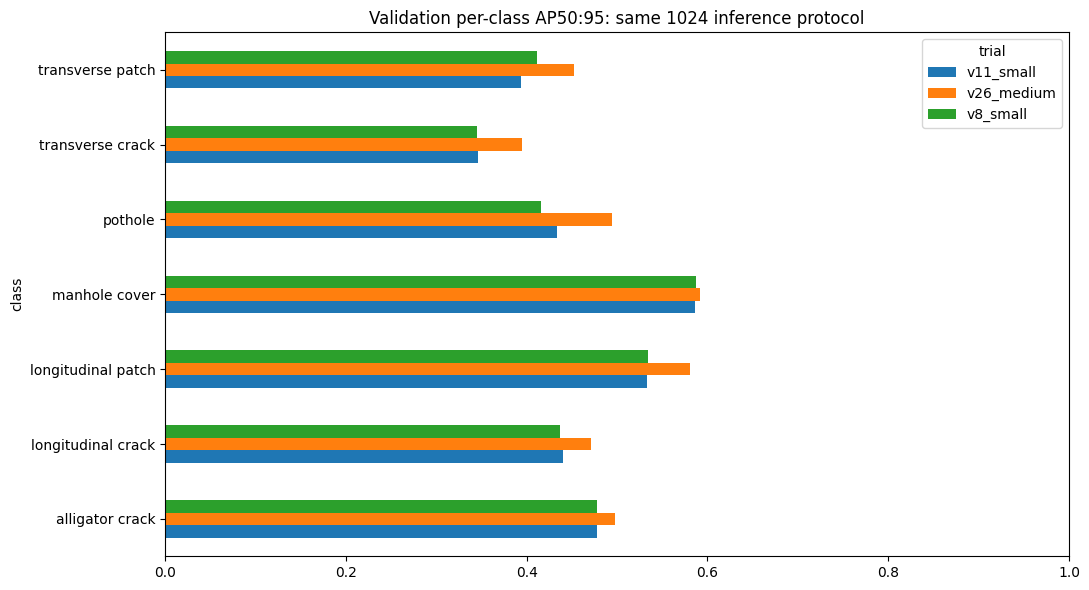

,contrast,reference,challenger,delta_map50_pp,delta_map50_95_pp,eval_imgsz
0,small_family_comparison,v8_small,v11_small,-0.271076,0.023483,1024


Experiment scope: {'controls_enabled': False, 'weighting_enabled': False, 'unweighted_complete': True, 'weighting_trial': None}


In [18]:
imbalance_table=class_support[class_support.split=='train'][['class','objects']].copy()
nominal_weights=imbalance_table['objects'].to_numpy(float)**(-0.5)
imbalance_table['projected_weight_at_cls_pw_05']=nominal_weights/nominal_weights.mean()
display(imbalance_table)
imbalance_table.to_csv(REPORTS/'planned_class_weights.csv',index=False)
print('Weights use training objects, not image folders; actual post-deduplication loader weights are saved by the worker.')
WEIGHTED_KEY = None
all_unweighted_complete = set(UNWEIGHTED_TRIALS) <= set(new_candidates())
if RUN_WEIGHTING_TRIAL and len(validation) and all_unweighted_complete:
    eligible = validation[(validation.train_imgsz == 1024) & (validation.cls_pw == 0)]
    if len(eligible):
        base_key = eligible.iloc[0]['trial']
        weighted_key = base_key+'_weighted'
        WEIGHTED_KEY = weighted_key
        TRIALS[weighted_key] = {**TRIALS[base_key], 'cls_pw':0.5}
        immutable_json(OUTPUT/'weighting_plan.json', {'trial':weighted_key,'base_trial':base_key,
            'settings':TRIALS[weighted_key],'data_id':DATA_ID,
            'base_checkpoint_sha256':CANDIDATES[base_key]['checkpoint_sha256']})
        if RUN_TRAINING: assert BUDGET_PASSED
        run_trial(weighted_key,TRIALS[weighted_key])
elif RUN_WEIGHTING_TRIAL:
    print('Weighting trial waits for all enabled unweighted runs and their validation results.')
CANDIDATES = {**legacy_candidates(), **new_candidates()}
validation = rank_validation(CANDIDATES) if VALIDATION_ENABLED else pd.DataFrame()
if len(validation):
    validation.to_csv(REPORTS/'validation_1024.csv',index=False)
    display(validation[['trial','model','origin','train_imgsz','eval_imgsz','actual_epochs','cls_pw','map50','map50_95']])
    validation_classes=pd.DataFrame([{'trial':key,**row} for key,record in CANDIDATES.items()
        for row in official_metrics(record)['perclass']])
    validation_classes.to_csv(REPORTS/'validation_perclass_1024.csv',index=False)
    display(validation_classes.pivot(index='class',columns='trial',values='ap50_95'))
    validation_classes.pivot(index='class',columns='trial',values='ap50_95').plot.barh(
        figsize=(11,6),xlim=(0,1),title='Validation per-class AP50:95: same 1024 inference protocol')
    plt.tight_layout();plt.show()
    contrasts=[]
    for label,reference,challenger in [
        ('training_resolution','control_640','control_1024'),
        ('YOLO26_capacity','control_1024','v26_medium'),
        ('small_family_comparison','v8_small','v11_small')]:
        if reference in set(validation.trial) and challenger in set(validation.trial):
            indexed=validation.set_index('trial')
            contrasts.append({'contrast':label,'reference':reference,'challenger':challenger,
                'delta_map50_pp':100*float(indexed.loc[challenger,'map50']-indexed.loc[reference,'map50']),
                'delta_map50_95_pp':100*float(indexed.loc[challenger,'map50_95']-indexed.loc[reference,'map50_95']),
                'eval_imgsz':EVAL_SIZE})
    if WEIGHTED_KEY is not None and WEIGHTED_KEY in set(validation.trial):
        base_key=json.loads((OUTPUT/'weighting_plan.json').read_text())['base_trial']
        indexed=validation.set_index('trial')
        contrasts.append({'contrast':'class_weighting','reference':base_key,'challenger':WEIGHTED_KEY,
            'delta_map50_pp':100*float(indexed.loc[WEIGHTED_KEY,'map50']-indexed.loc[base_key,'map50']),
            'delta_map50_95_pp':100*float(indexed.loc[WEIGHTED_KEY,'map50_95']-indexed.loc[base_key,'map50_95']),
            'eval_imgsz':EVAL_SIZE})
    if contrasts:
        contrast_table=pd.DataFrame(contrasts);display(contrast_table)
        contrast_table.to_csv(REPORTS/'ablation_contrasts_validation.csv',index=False)
    print('Experiment scope:',{'controls_enabled':RUN_CONTROLS,'weighting_enabled':RUN_WEIGHTING_TRIAL,
        'unweighted_complete':all_unweighted_complete,'weighting_trial':WEIGHTED_KEY})
else: print('New results pending. No round-two score has been fabricated.')


## 11. Read the learning curves and the accuracy/cost trade-off

Compare validation AP across epochs and inspect each model's own loss trend.
Do not compare raw box/class loss magnitudes between different architectures or
weighted/unweighted objectives. A positive last-five-epoch AP slope suggests
that the 30-epoch budget may still be insufficient. It is not statistical proof.

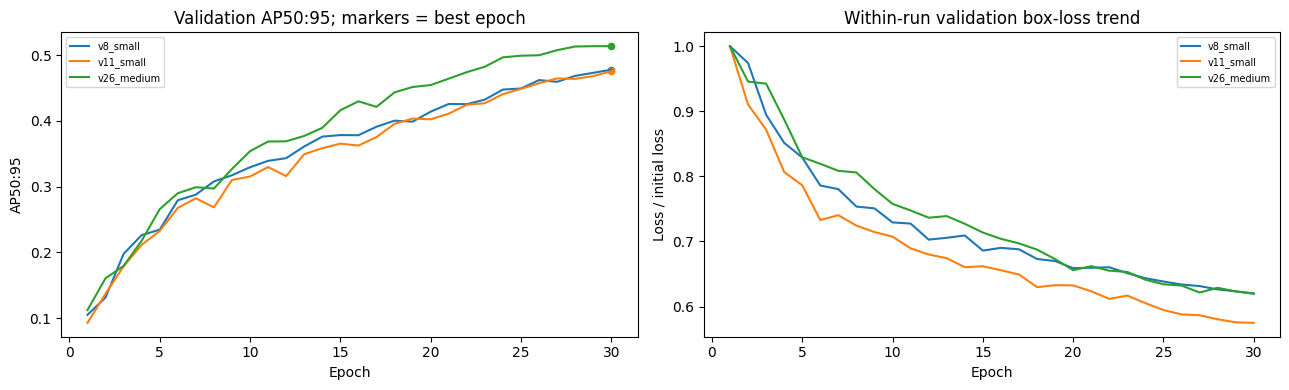

,trial,actual_epochs,best_epoch,last5_ap_slope,still_improving_indicator,training_minutes,checkpoint_MiB
0,v8_small,30,30,0.004530,True,63.345000,21.556437
1,v11_small,30,30,0.003978,True,67.188667,18.369715
2,v26_medium,30,30,0.003371,True,137.267167,42.076257


In [19]:
if not any(record['run'] for record in CANDIDATES.values()):
    print('No new training history yet. A learning curve is shown only after a real training run completes.')
else:
    curve_rows = []
    fig, axes = plt.subplots(1,2,figsize=(13,4))
    for key,record in CANDIDATES.items():
        if not record['run']: continue
        history = pd.read_csv(Path(record['run'])/'results.csv'); history.columns=history.columns.str.strip()
        x = history['epoch'].to_numpy(); y = history['metrics/mAP50-95(B)'].to_numpy()
        best = int(np.argmax(y)); axes[0].plot(x,y,label=key); axes[0].scatter([x[best]],[y[best]],s=20)
        loss = [c for c in history if c.startswith('val/') and 'loss' in c]
        if loss:
            initial = history[loss[0]].iloc[0]
            axes[1].plot(x,history[loss[0]]/initial,label=key)
        k=min(5,len(y)); slope=float(np.polyfit(np.arange(k),y[-k:],1)[0]) if k>1 else None
        seconds=recorded_training_seconds(Path(record['run']))
        curve_rows.append({'trial':key,'actual_epochs':len(history),'best_epoch':int(x[best]),
            'last5_ap_slope':slope,'still_improving_indicator':bool(slope is not None and slope>0.001),
            'training_minutes':seconds/60, 'checkpoint_MiB':Path(record['checkpoint']).stat().st_size/2**20})
    axes[0].set(title='Validation AP50:95; markers = best epoch',xlabel='Epoch',ylabel='AP50:95')
    axes[1].set(title='Within-run validation box-loss trend',xlabel='Epoch',ylabel='Loss / initial loss')
    for ax in axes:
        if ax.lines: ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()
    if curve_rows:
        training_summary=pd.DataFrame(curve_rows); display(training_summary)
        training_summary.to_csv(REPORTS/'training_summary.csv',index=False)

## 12. Validation error analysis and operating threshold

Rank models by validation mAP50:95, then mAP50, with a stable ID tie-break.
For that selected candidate, cache validation predictions once at confidence
0.001. Select a single deployment threshold over the declared 0.05–0.80 grid
using micro-F1 (tie-break: recall, then threshold). This chooses an operating
point; it does not calibrate scores into probabilities. AP is unchanged.

Failure examples below are validation diagnostics, not cherry-picked test
evidence. Review the original image and all annotations before attributing an
apparent false positive to the model. Small-object misses, class confusion,
localization and incomplete annotations require different remedies.

Validation-selected: v26_medium ; deployment confidence: 0.35


,confidence,tp,fp,fn,precision,recall,f1,matched_iou_mean
6,0.35,1759,466,797,0.790562,0.688185,0.735829,0.832389
7,0.40,1692,366,864,0.822157,0.661972,0.733420,0.835661
5,0.30,1822,616,734,0.747334,0.712833,0.729676,0.829319
4,0.25,1904,762,652,0.714179,0.744914,0.729223,0.825580
8,0.45,1609,304,947,0.841087,0.629499,0.720072,0.839449


,class,tp,fp,fn,fixed_precision,fixed_recall,fixed_f1
0,longitudinal crack,386,169,190,0.695495,0.670139,0.682582
1,transverse crack,281,153,133,0.647465,0.678744,0.662736
2,alligator crack,167,72,52,0.698745,0.762557,0.729258
3,pothole,85,38,26,0.691057,0.765766,0.726496
4,manhole cover,337,101,56,0.769406,0.857506,0.811071
5,longitudinal patch,408,121,98,0.771267,0.806324,0.788406
6,transverse patch,240,108,97,0.689655,0.712166,0.700730


,class,short_side_px_bucket,annotated,matched,recall
0,alligator crack,16–32,2,0,0.000000
1,alligator crack,>=32,217,167,0.769585
2,longitudinal crack,16–32,72,45,0.625000
3,longitudinal crack,8–16,20,10,0.500000
4,longitudinal crack,<8,5,2,0.400000
5,longitudinal crack,>=32,479,329,0.686848
6,longitudinal patch,16–32,120,92,0.766667
7,longitudinal patch,8–16,35,23,0.657143
8,longitudinal patch,<8,7,6,0.857143
9,longitudinal patch,>=32,344,287,0.834302


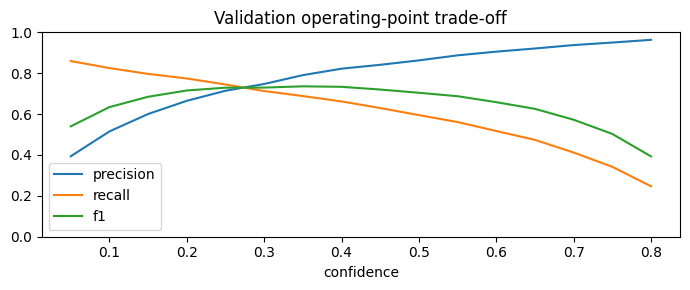

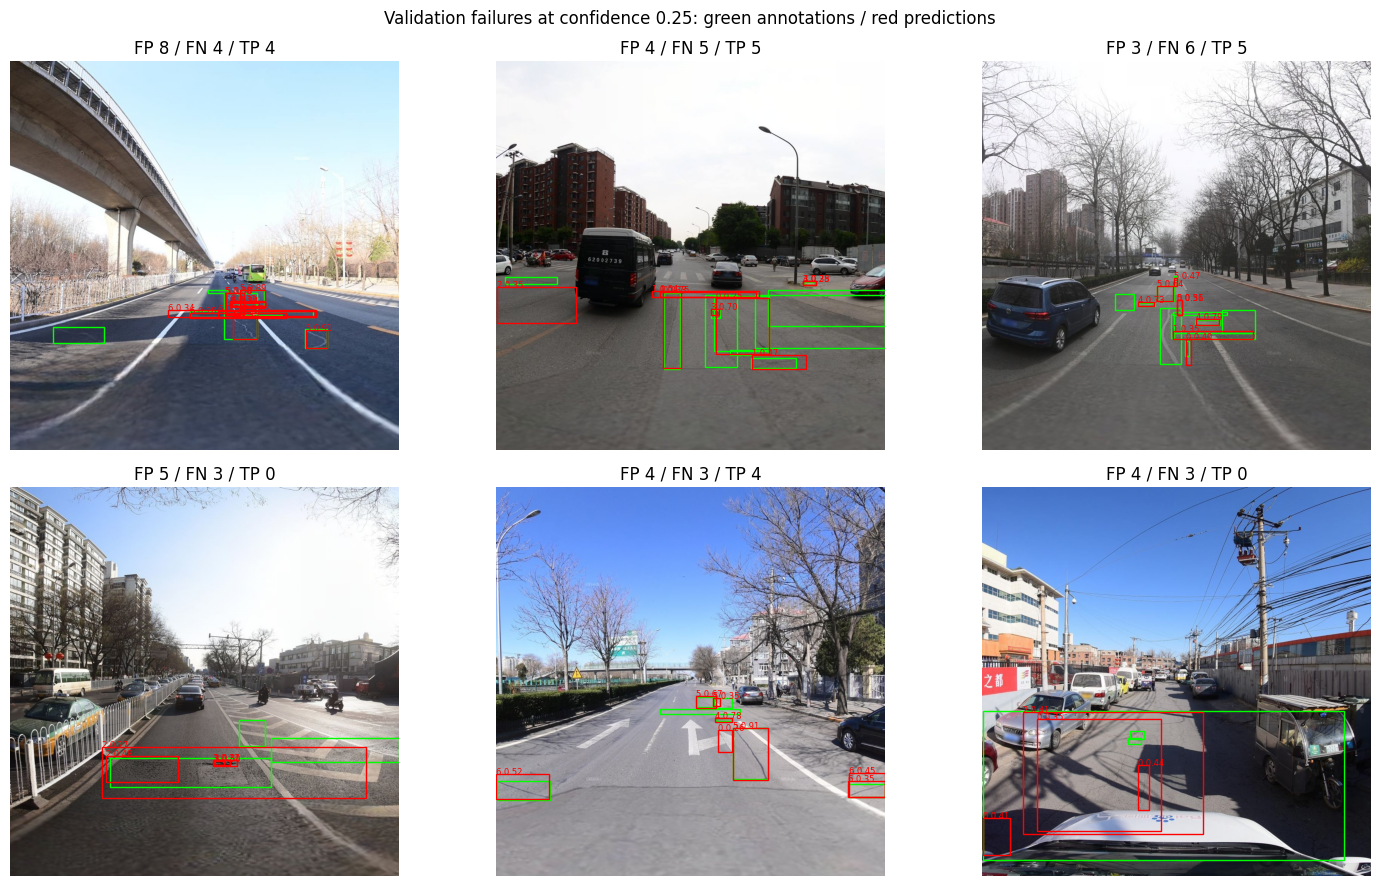

In [20]:
def cached_predictions(record, split, size=EVAL_SIZE):
    assert file_sha(record['checkpoint']) == record['checkpoint_sha256'], 'Checkpoint changed after registration.'
    identity = {'checkpoint':record['checkpoint_sha256'],'data':DATA_ID,'split':split,
        'imgsz':size,'floor':MAP_CONF,'iou':NMS_IOU,'max_det':MAX_DET,'quantize':32,'rect':False,'nms':True,
        'runtime':ultralytics.__version__}
    directory = EVALUATIONS/('predictions_'+digest(identity)[:20]); directory.mkdir(exist_ok=True)
    cache = directory/'boxes.npz'; paths = split_paths(split)
    if cache.exists():
        assert json.loads((directory/'identity.json').read_text()) == identity
        saved = np.load(cache,allow_pickle=False); flat=saved['boxes']; offsets=saved['offsets']
        assert len(offsets)==len(paths)+1
        return paths,[flat[offsets[i]:offsets[i+1]] for i in range(len(paths))]
    model=YOLO(record['checkpoint']); predictions=[prediction(model,p,size) for p in paths]
    offsets=np.concatenate(([0],np.cumsum([len(p) for p in predictions])))
    flat=np.concatenate(predictions,axis=0)
    temporary=directory/'boxes.tmp.npz'; np.savez_compressed(temporary,boxes=flat,offsets=offsets)
    atomic_json(directory/'identity.json',identity); os.replace(temporary,cache)
    del model;gc.collect();torch.cuda.empty_cache()
    return paths,predictions

def fixed_summary(paths,predictions,confidence):
    total=np.zeros((len(NAMES),3),dtype=int); overlaps=[]; examples=[]
    for image,all_boxes in zip(paths,predictions):
        boxes=all_boxes[all_boxes[:,1]>=confidence]; gt=ground_truth(image)
        counts_i,ious=match_boxes(gt,boxes);total+=counts_i;overlaps.extend(ious)
        examples.append({'image':str(image),'tp':int(counts_i[:,0].sum()),
            'fp':int(counts_i[:,1].sum()),'fn':int(counts_i[:,2].sum())})
    tp,fp,fn=map(int,total.sum(axis=0)); denominator=2*tp+fp+fn
    summary={'tp':tp,'fp':fp,'fn':fn,'precision':tp/(tp+fp) if tp+fp else 0.,
        'recall':tp/(tp+fn) if tp+fn else 0.,'f1':2*tp/denominator if denominator else 0.,
        'matched_iou_mean':float(np.mean(overlaps)) if overlaps else None}
    rows=[]
    for c,(t,p,n) in enumerate(total):
        rows.append({'class':NAMES[c],'tp':int(t),'fp':int(p),'fn':int(n),
            'fixed_precision':float(t/(t+p)) if t+p else 0.,'fixed_recall':float(t/(t+n)) if t+n else 0.,
            'fixed_f1':float(2*t/(2*t+p+n)) if 2*t+p+n else 0.})
    return summary,rows,examples

SELECTED = None; SELECTED_CONF = FIXED_CONF
if len(validation):
    SELECTED = CANDIDATES[validation.iloc[0]['trial']]
    val_paths,val_boxes=cached_predictions(SELECTED,'val')
    threshold_rows=[]
    for threshold in np.round(np.arange(.05,.801,.05),2):
        summary,_,_=fixed_summary(val_paths,val_boxes,float(threshold))
        threshold_rows.append({'confidence':float(threshold),**summary})
    threshold_table=pd.DataFrame(threshold_rows).sort_values(['f1','recall','confidence'],ascending=False)
    SELECTED_CONF=float(threshold_table.iloc[0]['confidence'])
    threshold_table.to_csv(REPORTS/'validation_thresholds.csv',index=False)
    print('Validation-selected:',SELECTED['trial'],'; deployment confidence:',SELECTED_CONF)
    display(threshold_table.head(5))
    fixed,classes,examples=fixed_summary(val_paths,val_boxes,FIXED_CONF)
    display(pd.DataFrame(classes))
    size_errors=[]
    for image,all_boxes in zip(val_paths,val_boxes):
        gt=ground_truth(image);filtered=all_boxes[all_boxes[:,1]>=FIXED_CONF]
        _,_,matched_ids=match_boxes(gt,filtered,return_indices=True)
        with Image.open(image) as im: width,height=im.size
        for index,(cls,x1,y1,x2,y2) in enumerate(gt):
            short=min(x2-x1,y2-y1)*EVAL_SIZE/max(width,height)
            bucket='<8' if short<8 else ('8–16' if short<16 else ('16–32' if short<32 else '>=32'))
            size_errors.append({'class':NAMES[int(cls)],'short_side_px_bucket':bucket,'matched':int(index in matched_ids)})
    recall_by_size=pd.DataFrame(size_errors).groupby(['class','short_side_px_bucket']).agg(
        annotated=('matched','size'),matched=('matched','sum')).reset_index()
    recall_by_size['recall']=recall_by_size['matched']/recall_by_size['annotated']
    display(recall_by_size);recall_by_size.to_csv(REPORTS/'validation_recall_by_object_size.csv',index=False)
    atomic_json(REPORTS/'validation_selection.json',{'candidate':SELECTED,'confidence':SELECTED_CONF,
        'rule':'validation mAP50:95, mAP50, stable trial ID; threshold by validation micro-F1',
        'threshold_grid':[r['confidence'] for r in threshold_rows], 'fixed_conf_025':fixed})
    curve=pd.DataFrame(threshold_rows).sort_values('confidence')
    curve.plot(x='confidence',y=['precision','recall','f1'],figsize=(7,3),ylim=(0,1),title='Validation operating-point trade-off')
    plt.tight_layout();plt.show()
    # Deterministic worst-error examples, tied by source path. Green = all GT; red = predictions.
    worst=sorted(examples,key=lambda r:(-(r['fp']+r['fn']),r['image']))[:6]
    lookup={str(p):i for i,p in enumerate(val_paths)}
    fig,axes=plt.subplots(2,3,figsize=(15,9))
    for ax,row in zip(axes.flat,worst):
        image=Path(row['image']); im=Image.open(image).convert('RGB');ax.imshow(im)
        for cls,x1,y1,x2,y2 in ground_truth(image):
            ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color='lime',linewidth=1))
        boxes=val_boxes[lookup[str(image)]]
        for cls,conf,x1,y1,x2,y2 in boxes[boxes[:,1]>=FIXED_CONF]:
            ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color='red',linewidth=1))
            ax.text(x1,y1,f'{int(cls)} {conf:.2f}',color='red',fontsize=6)
        ax.set_title(f"FP {row['fp']} / FN {row['fn']} / TP {row['tp']}");ax.axis('off')
    plt.suptitle('Validation failures at confidence 0.25: green annotations / red predictions')
    plt.tight_layout();plt.show()


## 13. Freeze decisions before evaluating the existing test benchmark

The primary comparison is validation-first. Do not change model settings because
of the test table. The test plan freezes checkpoint hashes, data identity,
resolution, thresholds, environment and selected winner. A repeated call loads
the same cached results; a changed plan is rejected within this output root.

All candidates use 1024 here, including attached legacy weights. Historical
640 scores stay in their own table. We also show the old 640 and new 1024
recipes together with explicit resolution labels; this is a practical recipe
comparison, not a controlled architecture-only claim.

The deadline configuration enables final evaluation automatically after all three
intended training runs and validation selection complete. Inspect the saved curves
and annotation/error examples when reviewing the results; report if training is
still underconverged. A new independent route/city holdout is needed for a fresh claim
of out-of-domain generalization.

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,128,293 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3846.7±801.3 MB/s, size: 313.1 KB)
val: Scanning /kaggle/working/svrdd_source/prepared/extracted/SVRDD_YOLO/Chaoyang/labels... 1000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 1.2Kit/s 0.8s0ss
val: New cache created: /kaggle/working/svrdd_source/prepared/extracted/SVRDD_YOLO/Chaoyang/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1000/1000 36.4it/s 27.5s.1ss
                   all       1000       2572      0.784      0.653      0.736      0.452
Speed: 2.1ms preprocess, 19.5ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/road_models_v2/evaluation/v8_small_test_1024_a0badac7a276/validator
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CU

,trial,train_imgsz,eval_imgsz,actual_epochs,cls_pw,map50,map50_95,precision,recall,f1,fps,checkpoint_MiB
0,v8_small,1024,1024,30,0.0,0.736033,0.452433,0.667514,0.715008,0.690445,34.781141,21.556437
1,v11_small,1024,1024,30,0.0,0.719727,0.445500,0.685164,0.705677,0.695269,34.996828,18.369715
2,v26_medium,1024,1024,30,0.0,0.774251,0.495882,0.712597,0.750000,0.730820,15.505354,42.076257


,trial,origin,train_imgsz,eval_imgsz,actual_epochs,map50,map50_95,recall,fps
0,historical_yolov8n,historical_v1,640,640,20,0.609257,0.347669,0.585537,56.635907
1,historical_yolo11n,historical_v1,640,640,20,0.596054,0.337790,0.582426,54.246487
2,historical_yolo26n,historical_v1,640,640,20,0.616416,0.350531,0.590591,50.759905
3,v8_small,round2,1024,1024,30,0.736033,0.452433,0.715008,34.781141
4,v11_small,round2,1024,1024,30,0.719727,0.445500,0.705677,34.996828
5,v26_medium,round2,1024,1024,30,0.774251,0.495882,0.750000,15.505354


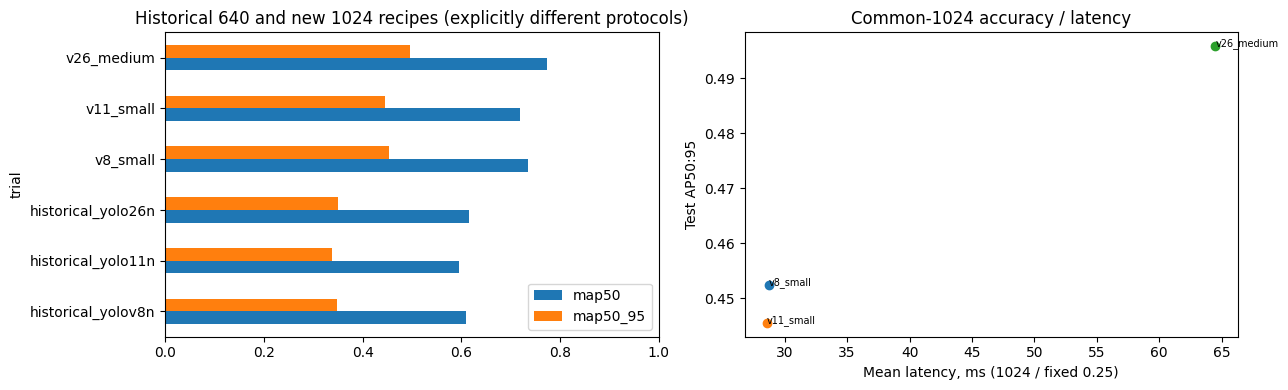

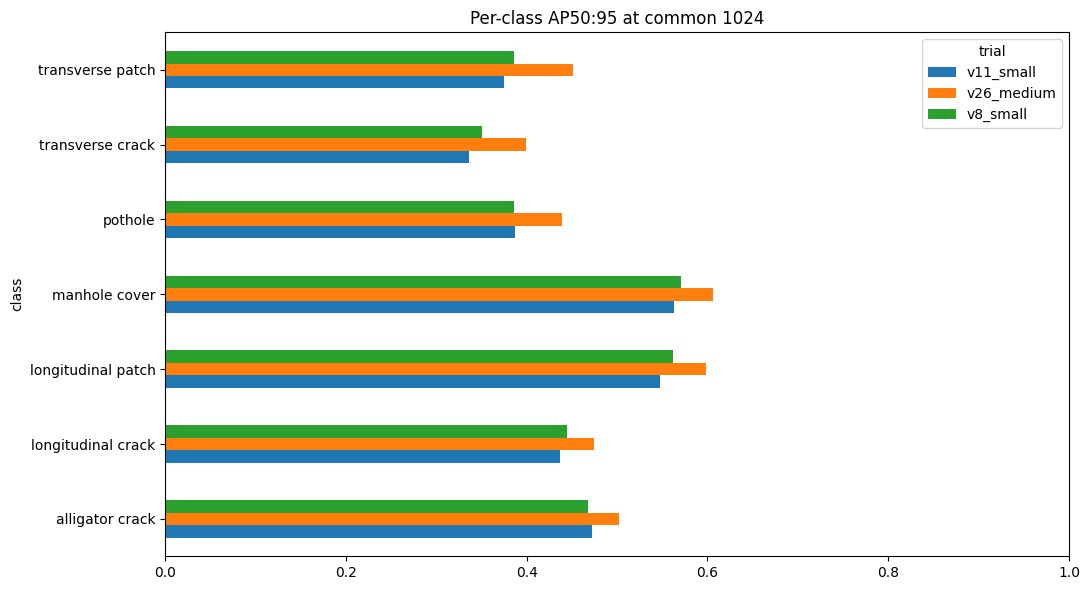

In [21]:
def benchmark(record, sample, confidence, size=EVAL_SIZE):
    assert file_sha(record['checkpoint']) == record['checkpoint_sha256'], 'Checkpoint changed after registration.'
    model=YOLO(record['checkpoint']);model.model.to('cuda:0')
    def call(image):
        result=model.predict(str(image),imgsz=size,device=0,batch=1,quantize=32,
            rect=False,conf=confidence,iou=NMS_IOU,max_det=MAX_DET,nms=True,verbose=False,save=False)[0]
        _=result.boxes.data.detach().cpu().numpy()
    for image in sample[:20]:call(image)
    torch.cuda.synchronize(0);resident=torch.cuda.memory_allocated(0);times=[];peaks=[]
    for image in sample:
        torch.cuda.synchronize(0);torch.cuda.reset_peak_memory_stats(0);start=time.perf_counter()
        call(image);torch.cuda.synchronize(0)
        times.append((time.perf_counter()-start)*1000);peaks.append(torch.cuda.max_memory_allocated(0))
    backend_e2e=bool(getattr(model.predictor.model,'end2end',False))
    assert not backend_e2e,'Expected common one-to-many + NMS path.'
    answer={'latency_mean_ms':float(np.mean(times)),'latency_p95_ms':float(np.percentile(times,95)),
        'fps':1000/float(np.mean(times)),'resident_MiB':resident/2**20,'peak_MiB':max(peaks)/2**20,
        'parameters':sum(p.numel() for p in model.model.parameters()),
        'checkpoint_MiB':Path(record['checkpoint']).stat().st_size/2**20,
        'timing_confidence':confidence,'timing_boundary':'warm-cache decode/preprocess/forward/NMS/CPU boxes; excludes drawing/load/network'}
    del model;gc.collect();torch.cuda.empty_cache();return answer

TEST_RESULTS = None
if RUN_FINAL_TEST:
    assert SELECTED is not None,'Train/evaluate candidates on validation first.'
    required=set(TRIALS)
    assert required <= set(CANDIDATES),'Some intended trials are unfinished; do not silently omit them.'
    assert not RUN_WEIGHTING_TRIAL or (WEIGHTED_KEY is not None and WEIGHTED_KEY in CANDIDATES), 'Complete the paired weighting trial first, or explicitly disable it before development.'
    test_plan={'dataset_id':DATA_ID,'candidates':CANDIDATES,'winner':SELECTED['trial'],
        'winner_confidence':SELECTED_CONF,'fixed_conf':FIXED_CONF,'eval_imgsz':EVAL_SIZE,
        'quantize':32,'rect':False,'nms':True,'nms_iou':NMS_IOU,'map_conf':MAP_CONF,
        'max_det':MAX_DET,'timing_seed':SEED,'timed_images':100,'warmup':20,'environment':ENVIRONMENT}
    immutable_json(OUTPUT/'frozen_test_plan.json',test_plan)
    paths=split_paths('test'); sample_ids=np.random.default_rng(SEED).choice(len(paths),100,replace=False)
    sample=[paths[int(i)] for i in sample_ids]
    rows=[];perclass_rows=[]
    for key,record in CANDIDATES.items():
        saved_path=EVALUATIONS/(key+'_final.json')
        if saved_path.exists():
            saved=json.loads(saved_path.read_text());assert saved['plan_id']==digest(test_plan)
        else:
            maps=official_metrics(record,'test');ps,boxes=cached_predictions(record,'test')
            fixed,class_rows,_=fixed_summary(ps,boxes,FIXED_CONF)
            operating_conf=SELECTED_CONF if key==SELECTED['trial'] else FIXED_CONF
            operating,_,_=fixed_summary(ps,boxes,operating_conf)
            speed=benchmark(record,sample,FIXED_CONF)
            row={**record,'split':'test_regression','eval_imgsz':EVAL_SIZE,
                'map50':maps['map50'],'map50_95':maps['map50_95'],**fixed,**speed,
                'operating_confidence':operating_conf,'operating_precision':operating['precision'],
                'operating_recall':operating['recall'],'operating_f1':operating['f1']}
            if key==SELECTED['trial'] and operating_conf!=FIXED_CONF:
                deployed_speed=benchmark(record,sample,operating_conf)
                row.update(deployment_latency_ms=deployed_speed['latency_mean_ms'],deployment_fps=deployed_speed['fps'])
            ap={x['class']:x for x in maps['perclass']}
            class_rows=[{'trial':key,**x,**ap.get(x['class'],{})} for x in class_rows]
            saved={'plan_id':digest(test_plan),'row':row,'perclass':class_rows}
            atomic_json(saved_path,saved)
        rows.append(saved['row']);perclass_rows.extend(saved['perclass'])
    TEST_RESULTS=pd.DataFrame(rows);TEST_PERCLASS=pd.DataFrame(perclass_rows)
    TEST_RESULTS.to_csv(REPORTS/'test_1024_comparison.csv',index=False)
    TEST_PERCLASS.to_csv(REPORTS/'test_perclass.csv',index=False)
    display(TEST_RESULTS[['trial','train_imgsz','eval_imgsz','actual_epochs','cls_pw','map50','map50_95','precision','recall','f1','fps','checkpoint_MiB']])
    historical_rows=historical_test.assign(trial=lambda x:'historical_'+x['model'],
        train_imgsz=640,eval_imgsz=640,actual_epochs=20,cls_pw=0,origin='historical_v1',split='test_regression')
    combined=pd.concat([historical_rows,TEST_RESULTS],ignore_index=True)
    combined.to_csv(REPORTS/'historical_and_new_recipes.csv',index=False)
    display(combined[['trial','origin','train_imgsz','eval_imgsz','actual_epochs','map50','map50_95','recall','fps']])
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    combined.set_index('trial')[['map50','map50_95']].plot.barh(ax=axes[0]);axes[0].set_xlim(0,1)
    axes[0].set_title('Historical 640 and new 1024 recipes (explicitly different protocols)')
    for _,r in TEST_RESULTS.iterrows():
        axes[1].scatter(r['latency_mean_ms'],r['map50_95']);axes[1].annotate(r['trial'],(r['latency_mean_ms'],r['map50_95']),fontsize=7)
    axes[1].set(xlabel='Mean latency, ms (1024 / fixed 0.25)',ylabel='Test AP50:95',title='Common-1024 accuracy / latency')
    plt.tight_layout();plt.show()
    TEST_PERCLASS.pivot(index='class',columns='trial',values='ap50_95').plot.barh(figsize=(11,6),xlim=(0,1),title='Per-class AP50:95 at common 1024')
    plt.tight_layout();plt.show()
else: print('Final test switch is off. Validation is the development surface.')


## 14. Export the validation-selected model and its inference contract

Export follows the completed comparison. Save **the selected winner**, not the
last-trained model. The package includes the exact inference size, confidence,
NMS, padding and class order alongside model/data identities and comparison
tables. The old app's 640-pixel defaults must be updated to consume this contract
before claiming deployment parity. A GPU reload check is not desktop UI validation.

Keep all training candidates and resumable states in saved Kaggle outputs. The
compact package contains only the selected inference checkpoint and reports;
it does not include raw data or optimizer checkpoints. Save Version with outputs
and verify persistence before stopping the session. Nothing downloads to Windows
or publishes an app automatically.

In [22]:
if RUN_FINAL_TEST and TEST_RESULTS is not None:
    export=OUTPUT/'export';export.mkdir(exist_ok=True)
    shutil.copy2(SELECTED['checkpoint'],export/'best.pt')
    assert file_sha(export/'best.pt') == SELECTED['checkpoint_sha256'], 'Export differs from frozen selected checkpoint.'
    contract={'model':SELECTED['model'],'trial':SELECTED['trial'],'names':NAMES,
        'imgsz':EVAL_SIZE,'confidence':SELECTED_CONF,'quantize':32,'rect':False,
        'nms':True,'iou':NMS_IOU,'max_det':MAX_DET,'checkpoint_sha256':file_sha(export/'best.pt'),
        'data_id':DATA_ID,'selection':'validation mAP50:95, then mAP50; validation threshold',
        'ultralytics':ultralytics.__version__,'desktop_app_verified':False}
    atomic_json(export/'inference_contract.json',contract)
    atomic_json(export/'labels.json',NAMES)
    model=YOLO(str(export/'best.pt'));assert list(model.names.values())==NAMES
    probe=model.predict(str(split_paths('val')[0]),imgsz=EVAL_SIZE,conf=SELECTED_CONF,
        quantize=32,device=0,rect=False,nms=True,iou=NMS_IOU,max_det=MAX_DET,verbose=False)
    assert len(probe)==1
    del model,probe;gc.collect();torch.cuda.empty_cache()
    for item in ['data_identity.json','environment.json','frozen_test_plan.json']:
        shutil.copy2(OUTPUT/item,export/item)
    if SELECTED['run']:
        for name in ['training_spec.json','class_weights.json','complete.json']:
            shutil.copy2(Path(SELECTED['run'])/name,export/name)
    if (OUTPUT/'weighting_plan.json').exists(): shutil.copy2(OUTPUT/'weighting_plan.json',export/'weighting_plan.json')
    shutil.copy2(Path(dataset_yaml).parent/'split_audit.json',export/'split_audit.json')
    shutil.copytree(OUTPUT/'data_diagnostics',export/'data_diagnostics',dirs_exist_ok=True)
    for report in REPORTS.glob('*'):
        if report.is_file():shutil.copy2(report,export/report.name)
    members={str(p.relative_to(export)):file_sha(p) for p in export.rglob('*') if p.is_file() and p.name!='checksums.json'}
    atomic_json(export/'checksums.json',members)
    archive=Path(shutil.make_archive(str(OUTPUT/'road_damage_v2_selected'),'zip',export))
    assert archive.stat().st_size < 200*2**20,'Package exceeds 200 MiB; inspect before downloading.'
    print('Verified selected-model package:',archive,'MiB:',round(archive.stat().st_size/2**20,2))
else: print('Export pending: finish and freeze the new comparison first.')


Verified selected-model package: /kaggle/working/road_models_v2/road_damage_v2_selected.zip MiB: 40.96


## 15. Hyperparameter Tuning

In [23]:
# Paste this entire file into one CODE cell at the END of the current notebook.
# Run the notebook's setup/data/recovery/validation cells first.
# Change only RUN_OPTUNA to True when ready to spend GPU time.
RUN_OPTUNA = True
HPO_TARGET_TRIALS = 3             # TOTAL per model, including the reference trial.
HPO_EPOCHS = 3                    # EXTRA epochs per trial, starting from v2 best.pt.
HPO_MAX_WALL_HOURS = 2.0          # Cumulative worker time, including validation.
HPO_MAX_TRIAL_MINUTES = 20        # Cumulative training time for each individual trial.
HPO_ROOT = "/kaggle/working/road_models_v3_tuning"
HPO_RESTORE_FROM = None           # Optional attached saved road_models_v3_tuning folder.

from pathlib import Path
import ast, gc, hashlib, json, math, os, shutil, signal, subprocess, sys, time


def _hpo_sha(path):
    checksum = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            checksum.update(block)
    return checksum.hexdigest()


def _hpo_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False,
                                    separators=(",", ":")).encode()).hexdigest()


def _hpo_json(path, value, immutable=False):
    path = Path(path)
    if immutable and path.exists():
        if json.loads(path.read_text()) != value:
            raise ValueError(f"Experiment identity changed: {path}. Use a new HPO_ROOT.")
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    os.replace(temporary, path)


def _hpo_spent(root, job=None):
    # An unclosed attempt is charged up to the current time. Session loss cannot
    # silently reset the budget. A restored stale attempt is therefore conservative.
    total = 0.0
    for path in Path(root).glob("attempts/*.json"):
        record = json.loads(path.read_text())
        if job is None or record["job"] == job:
            total += max(0.0, record.get("finished", time.time()) - record["started"])
    return total


def _hpo_launch(command, root, job, job_cap_seconds):
    remaining = min(HPO_MAX_WALL_HOURS * 3600 - _hpo_spent(root),
                    job_cap_seconds - _hpo_spent(root, job))
    if remaining <= 0:
        raise TimeoutError("Tuning time budget exhausted. Saved trials/checkpoints are retained.")
    attempts = Path(root) / "attempts"
    attempts.mkdir(exist_ok=True)
    token = f"{time.time_ns()}-{os.getpid()}"
    path = attempts / (token + ".json")
    logfile = attempts / (token + ".log")
    record = {"job": job, "started": time.time(), "command": command,
              "log": str(logfile)}
    _hpo_json(path, record)
    process = None
    try:
        with logfile.open("w") as log:
            process = subprocess.Popen(command, stdout=log, stderr=subprocess.STDOUT,
                                       start_new_session=True)
            next_update = time.monotonic() + 30
            deadline = time.monotonic() + remaining
            while process.poll() is None:
                if time.monotonic() >= deadline:
                    raise TimeoutError(f"{job}: time cap reached. Rerun this cell to resume "
                                       "only after explicitly extending the exhausted budget.")
                if time.monotonic() >= next_update:
                    print(f"  {job}: running; log {logfile}", flush=True)
                    next_update = time.monotonic() + 30
                time.sleep(1)
            if process.returncode:
                tail = "\n".join(logfile.read_text(errors="replace").splitlines()[-45:])
                raise RuntimeError(f"{job} failed; settings were not changed.\n{tail}")
    finally:
        if process is not None and process.poll() is None:
            os.killpg(process.pid, signal.SIGTERM)
            try:
                process.wait(timeout=20)
            except subprocess.TimeoutExpired:
                os.killpg(process.pid, signal.SIGKILL)
                process.wait()
        record.update(finished=time.time(), exit_code=None if process is None else process.returncode)
        _hpo_json(path, record)


# Separate validation subprocess: GPU 0, FP32, batch 1, validation split ONLY.
HPO_VALIDATOR_SOURCE = r'''
from pathlib import Path
import hashlib, json, math, os, sys
import numpy as np
from ultralytics import YOLO
p = json.loads(Path(sys.argv[1]).read_text())
assert hashlib.sha256(Path(p['checkpoint']).read_bytes()).hexdigest() == p['checkpoint_sha256']
model = YOLO(p['checkpoint'])
assert list(model.names.values()) == p['names']
result = model.val(data=p['data'], split='val', imgsz=1024, batch=1, device=0,
    quantize=32, rect=False, conf=0.001, iou=0.7, max_det=300, nms=True,
    plots=False, save_json=False, project=p['project'], name='validator',
    exist_ok=True, verbose=False)
box = result.box
aps = np.asarray(box.all_ap)
assert np.isfinite([box.map50, box.map, *aps.ravel()]).all()
rows = [{'class':p['names'][int(c)], 'ap50':float(aps[j,0]),
         'ap50_95':float(aps[j].mean()), 'validator_precision':float(box.p[j]),
         'validator_recall':float(box.r[j])}
        for j,c in enumerate(box.ap_class_index)]
answer = {'identity':p, 'map50':float(box.map50), 'map50_95':float(box.map),
          'perclass':rows}
target = Path(p['project'])/'validation.json'
temporary = target.with_suffix('.tmp')
temporary.write_text(json.dumps(answer, indent=2, allow_nan=False))
os.replace(temporary, target)
'''


def _hpo_validate(checkpoint, directory, root, validator_path):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    identity = {"checkpoint": str(checkpoint), "checkpoint_sha256": _hpo_sha(checkpoint),
                "names": NAMES, "data": str(dataset_yaml), "data_id": DATA_ID,
                "project": str(directory), "protocol": "val-1024-FP32-NMS-batch1",
                "validator_sha256": _hpo_sha(validator_path),
                "environment": ENVIRONMENT["packages"]}
    _hpo_json(directory / "validation_input.json", identity, immutable=True)
    cache = directory / "validation.json"
    if not cache.exists():
        _hpo_launch([sys.executable, str(validator_path), str(directory / "validation_input.json")],
                    root, "validation:" + str(directory.relative_to(root)), 600)
    saved = json.loads(cache.read_text())
    if saved["identity"] != identity or not all(math.isfinite(saved[k]) for k in ("map50", "map50_95")):
        raise ValueError(f"Invalid/stale validation cache: {cache}")
    return saved


def _hpo_run_study(optuna, study, target, evaluate):
    """Resume RUNNING trials before asking for new ones. The limit is a TOTAL."""
    state = optuna.trial.TrialState
    while True:
        running = study.get_trials(deepcopy=False, states=(state.RUNNING,))
        if len(running) > 1:
            raise RuntimeError("More than one running trial exists. Use only one tuning runner.")
        if running:
            trial = running[0]
            if set(trial.params) != {"lr0", "cls_pw"}:
                raise RuntimeError("A trial was interrupted while sampling parameters. "
                                   "Inspect the study before continuing; no new training was started.")
        else:
            attempted = study.get_trials(deepcopy=False,
                                         states=(state.COMPLETE, state.FAIL, state.PRUNED))
            if len(attempted) >= target:
                return
            # Reconstruct from history with a trial-specific seed, including after restart.
            study.sampler = optuna.samplers.TPESampler(seed=2026 + len(attempted),
                                                       n_startup_trials=2)
            live = study.ask(fixed_distributions={
                "lr0": optuna.distributions.FloatDistribution(1e-5, 3e-4, log=True),
                "cls_pw": optuna.distributions.CategoricalDistribution([0.0, 0.5]),
            })
            trial = next(t for t in study.get_trials(deepcopy=False) if t.number == live.number)
        try:
            score = evaluate(trial.number, dict(trial.params))
            if not math.isfinite(score):
                raise ValueError("Trial produced a non-finite validation score.")
        except (TimeoutError, KeyboardInterrupt):
            # Remain RUNNING so the same trial directory/optimizer checkpoint resumes.
            raise
        except Exception:
            study.tell(trial.number, state=state.FAIL)
            raise
        study.tell(trial.number, score)


def _hpo_main():
    import importlib.util
    required = ["COMMON", "TRIALS", "WORKER_SOURCE", "DATA_ID", "ENVIRONMENT",
                "dataset_yaml", "NAMES", "completed_status", "trial_dir"]
    missing = [key for key in required if key not in globals()]
    if missing:
        raise RuntimeError("Run setup, dataset, recovery, and model cells first. Missing: " + ", ".join(missing))
    if RUN_TRAINING or not REUSE_TRAINED_MODELS:
        raise RuntimeError("Keep REUSE_TRAINED_MODELS=True and RUN_TRAINING=False for original models.")
    if not isinstance(HPO_TARGET_TRIALS, int) or HPO_TARGET_TRIALS < 2:
        raise ValueError("Use at least two trials per model, including the reference.")
    if not isinstance(HPO_EPOCHS, int) or HPO_EPOCHS < 2:
        raise ValueError("Use at least two extra epochs per trial.")
    if not all(math.isfinite(x) and x > 0 for x in [HPO_MAX_WALL_HOURS, HPO_MAX_TRIAL_MINUTES]):
        raise ValueError("Time budgets must be positive finite numbers.")
    import torch, ultralytics
    if os.name != "posix" or torch.cuda.device_count() != 2:
        raise RuntimeError("This cell requires Kaggle Linux with GPU T4 x2.")
    if ultralytics.__version__ != "8.4.191":
        raise RuntimeError("Keep the notebook's audited ultralytics==8.4.191.")
    sources = {
        "v8_small": ("yolov8s", "/kaggle/input/datasets/solaymanabdelfattah/3x-v2-models/v2/yolov8n/best.pt",
                     "5a5b96a5204dffb8371ea621b6461bc3939ec0b11fc9f6ebfbc3af38d684a3ba"),
        "v11_small": ("yolo11s", "/kaggle/input/datasets/solaymanabdelfattah/3x-v2-models/v2/yolov11s/best.pt",
                      "aed9032517943b4a5ffe30a01a74c974bc8e7e625b6b7a6e6ede1f688e1a6c63"),
        "v26_medium": ("yolo26m", "/kaggle/input/datasets/solaymanabdelfattah/3x-v2-models/v2/yolo26m/best.pt",
                       "fab0e117d8871eeea47a45a98e33963a524b7751bae793c796258bf1a457c0c4"),
    }
    for key, (model, source, checksum) in sources.items():
        if not Path(source).is_file() or _hpo_sha(source) != checksum:
            raise ValueError(f"Missing or changed trained Kaggle input: {source}")
        if TRIALS[key]["model"] != model:
            raise ValueError(f"{key}: original notebook architecture changed.")
        completed_status(trial_dir(key, TRIALS[key]), TRIALS[key])
    if importlib.util.find_spec("optuna") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna==4.5.0"])
    import optuna
    import pandas as pd
    import fcntl
    root = Path(HPO_ROOT)
    if not root.is_absolute() or not root.resolve().is_relative_to(Path("/kaggle/working")):
        raise ValueError("HPO_ROOT must be below /kaggle/working.")
    if HPO_RESTORE_FROM is not None and not (root / "plan.json").exists():
        restore = Path(HPO_RESTORE_FROM).resolve()
        if not restore.is_relative_to(Path("/kaggle/input")) or not (restore / "plan.json").is_file():
            raise ValueError("Point HPO_RESTORE_FROM to your attached saved tuning output folder.")
        if root.exists():
            raise ValueError("Restore into a fresh HPO_ROOT; do not merge experiments.")
        shutil.copytree(restore, root, ignore=shutil.ignore_patterns(".runner.lock"))
    root.mkdir(parents=True, exist_ok=True)
    with (root / ".runner.lock").open("a") as lock:
        try:
            fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            raise RuntimeError("Another tuning cell is already running in this output folder.")
        # Reuse the notebook's checked DDP worker, but with NEW trial directories
        # and your road-trained input as 'pretrained'. No baseline globals are changed.
        ast.parse(WORKER_SOURCE)
        train_worker = root / "training_worker.py"
        val_worker = root / "validation_worker.py"
        fixed = {**COMMON, "epochs": HPO_EPOCHS, "patience": HPO_EPOCHS + 1,
                 "imgsz": 1024, "batch": 8, "device": [0, 1], "optimizer": "AdamW",
                 "weight_decay": 0.0005, "lr0": 1e-4, "lrf": 0.1,
                 "warmup_epochs": 0.0, "warmup_bias_lr": 0.0,
                 "mosaic": 0.0, "close_mosaic": 0, "plots": False, "save_period": -1}
        plan = {"kind": "short warm-start fine-tuning search", "data_id": DATA_ID,
                "environment": ENVIRONMENT, "optuna": optuna.__version__, "sources": sources,
                "fixed_train": fixed, "search": {"lr0": [1e-5, 3e-4, "log"], "cls_pw": [0.0, 0.5]},
                "reference": {"lr0": 1e-4, "cls_pw": 0.0},
                "training_worker_sha256": hashlib.sha256(WORKER_SOURCE.encode()).hexdigest(),
                "validation_worker_sha256": hashlib.sha256(HPO_VALIDATOR_SOURCE.encode()).hexdigest()}
        # JSON roundtrip also normalizes tuples before comparing a restored plan.
        plan = json.loads(json.dumps(plan))
        _hpo_json(root / "plan.json", plan, immutable=True)
        _hpo_json(root / "limits.json", {"total_trials_per_model": HPO_TARGET_TRIALS,
                  "extra_epochs": HPO_EPOCHS, "max_wall_hours": HPO_MAX_WALL_HOURS,
                  "max_training_minutes_per_trial": HPO_MAX_TRIAL_MINUTES})
        train_worker.write_text(WORKER_SOURCE)
        val_worker.write_text(HPO_VALIDATOR_SOURCE)
        gc.collect()
        torch.cuda.empty_cache()
        print(f"Tuning: {len(sources)} models x {HPO_TARGET_TRIALS} total trials x "
              f"{HPO_EPOCHS} extra epochs. Both T4s train ONE trial at a time.", flush=True)
        print("Search: learning rate + class weighting; weight decay is fixed. "
              "Test and original model exports are untouched.", flush=True)
        storage = "sqlite:///" + str(root / "optuna.db")
        baseline_scores, studies = {}, {}

        def write_reports():
            rows, winners = [], []
            for key, study in studies.items():
                model, source, checksum = sources[key]
                base = baseline_scores[key]
                rows.append({"model": model, "kind": "original_v2", "trial": None,
                             "extra_epochs": 0, "map50_95": base["map50_95"],
                             "map50": base["map50"], "checkpoint": source,
                             "checkpoint_sha256": checksum})
                for trial in study.get_trials(deepcopy=False, states=(optuna.trial.TrialState.COMPLETE,)):
                    directory = root / key / f"trial_{trial.number:03d}"
                    metrics = json.loads((directory / "evaluation/validation.json").read_text())
                    ck = directory / "weights/best.pt"
                    if _hpo_sha(ck) != metrics["identity"]["checkpoint_sha256"]:
                        raise ValueError(f"Completed tuning checkpoint changed: {ck}")
                    rows.append({"model": model, "kind": "reference" if trial.number == 0 else "tuned",
                                 "trial": trial.number, "extra_epochs": HPO_EPOCHS,
                                 **trial.params, "map50_95": metrics["map50_95"],
                                 "map50": metrics["map50"], "checkpoint": str(ck),
                                 "checkpoint_sha256": _hpo_sha(ck)})
                family = sorted([r for r in rows if r["model"] == model],
                                key=lambda r: (-r["map50_95"], -r["map50"], r["extra_epochs"]))
                winners.append(family[0])
                study.trials_dataframe().to_csv(root / key / "optuna_trials.csv", index=False)
            table = pd.DataFrame(rows)
            table.to_csv(root / "validation_comparison.csv", index=False)
            _hpo_json(root / "validation_selected.json", {
                "scope": "provisional validation selection; short search, no new test/export",
                "plan_id": _hpo_digest(plan), "per_model": winners,
                "overall": sorted(winners, key=lambda r: (-r["map50_95"], -r["map50"]))[0]})
            return table

        for key, (model, source, checksum) in sources.items():
            (root / key).mkdir(exist_ok=True)
            baseline_scores[key] = _hpo_validate(source, root / key / "baseline", root, val_worker)
            study = optuna.create_study(study_name=key, storage=storage, direction="maximize",
                                        load_if_exists=True)
            studies[key] = study
            if not study.trials:
                study.enqueue_trial({"lr0": 1e-4, "cls_pw": 0.0})

            def evaluate(number, params):
                run = root / key / f"trial_{number:03d}"
                run.mkdir(parents=True, exist_ok=True)
                cfg = {**fixed, **params, "project": str(run.parent), "name": run.name}
                payload = {"train": cfg, "pretrained": source, "pretrained_sha256": checksum,
                           "dataset_id": DATA_ID, "environment": ENVIRONMENT["packages"],
                           "worker_sha256": _hpo_sha(train_worker)}
                payload_path = run / "training_spec.json"
                _hpo_json(payload_path, payload, immutable=True)
                print(f"{key} trial {number + 1}/{HPO_TARGET_TRIALS}: {params}", flush=True)
                if not (run / "complete.json").exists():
                    command = [sys.executable, "-m", "torch.distributed.run", "--standalone",
                               "--nproc_per_node=2", str(train_worker), str(payload_path)]
                    # Resume interrupted trials only from THEIR optimizer checkpoint.
                    # A final saved epoch can recover its metadata without more training.
                    if (run / "weights/last-resumable.pt").exists() and (run / "results.csv").exists():
                        if len(pd.read_csv(run / "results.csv")) == HPO_EPOCHS:
                            command.append("--recover-only")
                    elif (run / "results.csv").exists() or (run / "weights/best.pt").exists():
                        raise RuntimeError(f"{run}: partial output has no resumable state. "
                                           "No automatic restart was attempted.")
                    _hpo_launch(command, root, "train:" + str(run.relative_to(root)),
                                HPO_MAX_TRIAL_MINUTES * 60)
                completed_status(run, cfg)
                metrics = _hpo_validate(run / "weights/best.pt", run / "evaluation", root, val_worker)
                print(f"  validation mAP50-95: {metrics['map50_95']:.4f}", flush=True)
                return metrics["map50_95"]

            try:
                _hpo_run_study(optuna, study, HPO_TARGET_TRIALS, evaluate)
            finally:
                # Also retain a readable report if a later trial hits an error or cap.
                write_reports()
        table = write_reports()
        print(table[["model", "kind", "trial", "extra_epochs", "map50_95", "map50"]].to_string(index=False))
        print(f"Reports, study database and trial checkpoints: {root}")
        print("Save Version WITH OUTPUTS before stopping Kaggle. For another session, "
              "attach that output and set HPO_RESTORE_FROM to its tuning folder.")
        print("This is a small exploratory search. Confirm the best recipe against "
              "its reference with equal additional epochs before the final test/export.")


if RUN_OPTUNA:
    _hpo_main()
else:
    print("Tuning is OFF. Set RUN_OPTUNA=True in this cell when ready. "
          "Leave original RUN_TRAINING=False.")


Tuning: 3 models x 3 total trials x 3 extra epochs. Both T4s train ONE trial at a time.
Search: learning rate + class weighting; weight decay is fixed. Test and original model exports are untouched.
  validation:v8_small/baseline: running; log /kaggle/working/road_models_v3_tuning/attempts/1793653951785754014-150.log


[I 2026-11-02 21:13:07,698] A new study created in RDB with name: v8_small


v8_small trial 1/3: {'lr0': 0.0001, 'cls_pw': 0.0}
  train:v8_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793653987781506882-150.log
  train:v8_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793653987781506882-150.log
  train:v8_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793653987781506882-150.log
  train:v8_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793653987781506882-150.log
  train:v8_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793653987781506882-150.log
  train:v8_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793653987781506882-150.log
  train:v8_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793653987781506882-150.log
  train:v8_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793653987781506882-150.log
  train:v8_small/tria

[I 2026-11-02 21:34:20,380] A new study created in RDB with name: v11_small


v11_small trial 1/3: {'lr0': 0.0001, 'cls_pw': 0.0}
  train:v11_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793655260452794734-150.log
  train:v11_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793655260452794734-150.log
  train:v11_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793655260452794734-150.log
  train:v11_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793655260452794734-150.log
  train:v11_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793655260452794734-150.log
  train:v11_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793655260452794734-150.log
  train:v11_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793655260452794734-150.log
  train:v11_small/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793655260452794734-150.log
  train:v11_

[I 2026-11-02 21:57:46,292] A new study created in RDB with name: v26_medium


v26_medium trial 1/3: {'lr0': 0.0001, 'cls_pw': 0.0}
  train:v26_medium/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793656666361767847-150.log
  train:v26_medium/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793656666361767847-150.log
  train:v26_medium/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793656666361767847-150.log
  train:v26_medium/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793656666361767847-150.log
  train:v26_medium/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793656666361767847-150.log
  train:v26_medium/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793656666361767847-150.log
  train:v26_medium/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793656666361767847-150.log
  train:v26_medium/trial_000: running; log /kaggle/working/road_models_v3_tuning/attempts/1793656666361767847-150.log
  t

In [ ]:
# Paste this entire file into ONE new code cell AFTER the finished Optuna cell.
# Run this cell once. It evaluates and exports; it never trains.
from pathlib import Path
import json, shutil, sqlite3, zipfile


def finalize_road_tuning():
    global EVALUATIONS
    required = ["DATA_ID", "ENVIRONMENT", "NAMES", "OUTPUT", "REPORTS", "EVALUATIONS",
                "TRIALS", "SEED", "EVAL_SIZE", "FIXED_CONF", "MAP_CONF", "NMS_IOU", "MAX_DET",
                "digest", "file_sha", "atomic_json", "immutable_json", "completed_status",
                "official_metrics", "cached_predictions", "fixed_summary", "benchmark",
                "split_paths", "dataset_yaml", "YOLO", "np", "pd", "torch", "gc", "display"]
    missing = [name for name in required if name not in globals()]
    if missing:
        raise RuntimeError("Run this after the original notebook and Optuna finish. Missing: " + ", ".join(missing))
    root = Path(globals().get("HPO_ROOT", "/kaggle/working/road_models_v3_tuning"))
    plan = json.loads((root / "plan.json").read_text())
    selection = json.loads((root / "validation_selected.json").read_text())
    limits = json.loads((root / "limits.json").read_text())
    scores = pd.read_csv(root / "validation_comparison.csv")
    if plan["data_id"] != DATA_ID or plan["environment"] != ENVIRONMENT:
        raise ValueError("Current data/runtime differs from the tuning experiment.")
    if selection["plan_id"] != digest(plan):
        raise ValueError("Selection belongs to a different tuning plan.")
    expected_models = {source[0] for source in plan["sources"].values()}
    if {row["model"] for row in selection["per_model"]} != expected_models or len(selection["per_model"]) != 3:
        raise ValueError("All three model studies must finish first.")
    for model in expected_models:
        finished = scores[(scores.model == model) & (scores.kind != "original_v2")]
        if len(finished) != limits["total_trials_per_model"]:
            raise ValueError(f"{model}: not all intended trials have completed successfully.")
    if selection["overall"] not in selection["per_model"]:
        raise ValueError("Overall selection is not one of the family winners.")
    if (EVAL_SIZE, FIXED_CONF, MAP_CONF, NMS_IOU, MAX_DET) != (1024, 0.25, 0.001, 0.7, 300):
        raise ValueError("Keep the original common evaluation settings.")

    records = {}
    for row in selection["per_model"]:
        model = row["model"]
        key = next(k for k, source in plan["sources"].items() if source[0] == model)
        checkpoint = Path(row["checkpoint"])
        if file_sha(checkpoint) != row["checkpoint_sha256"]:
            raise ValueError(f"Selected checkpoint changed: {checkpoint}")
        base_epochs = int(TRIALS[key]["epochs"])
        extra = int(row["extra_epochs"])
        if extra:
            run = checkpoint.parent.parent
            payload = json.loads((run / "training_spec.json").read_text())
            status = completed_status(run, payload["train"])
            if payload["pretrained_sha256"] != plan["sources"][key][2]:
                raise ValueError("Fine-tune parent model differs from the recorded original.")
            extra = int(status["actual_epochs"])
            candidate_id = f"{key}_tuned_{int(row['trial']):03d}"
            power = float(payload["train"]["cls_pw"])
        else:
            run = None
            candidate_id = key + "_original_v2"
            power = 0.0
        records[candidate_id] = {
            "trial": candidate_id, "model": model, "checkpoint": str(checkpoint),
            "checkpoint_sha256": row["checkpoint_sha256"], "run": str(run) if run else None,
            "origin": "round3_tuning_selection", "train_imgsz": 1024,
            "base_epochs": base_epochs, "extra_epochs": extra,
            "actual_epochs": base_epochs + extra, "planned_epochs": base_epochs + int(row["extra_epochs"]),
            "cls_pw": power, "status": "validation_selected",
            "validation_map50_95": row["map50_95"], "validation_map50": row["map50"],
        }
    winner = next(r for r in records.values()
                  if r["checkpoint_sha256"] == selection["overall"]["checkpoint_sha256"])
    final = root / "final"
    final.mkdir(exist_ok=True)
    original_evaluations = EVALUATIONS
    EVALUATIONS = final / "evaluation"
    EVALUATIONS.mkdir(exist_ok=True)
    try:
        # Choose deployment confidence exclusively on validation, before any new test call.
        val_paths, val_boxes = cached_predictions(winner, "val")
        thresholds = []
        for confidence in np.round(np.arange(0.05, 0.801, 0.05), 2):
            summary, _, _ = fixed_summary(val_paths, val_boxes, float(confidence))
            thresholds.append({"confidence": float(confidence), **summary})
        threshold_table = pd.DataFrame(thresholds).sort_values(
            ["f1", "recall", "confidence"], ascending=False)
        chosen_confidence = float(threshold_table.iloc[0]["confidence"])
        threshold_table.to_csv(final / "validation_thresholds.csv", index=False)
        frozen = {"tuning_plan_id": selection["plan_id"], "dataset_id": DATA_ID,
                  "candidates": records, "winner": winner["trial"], "confidence": chosen_confidence,
                  "eval_imgsz": 1024, "quantize": 32, "rect": False, "nms": True,
                  "map_conf": MAP_CONF, "fixed_conf": FIXED_CONF, "iou": NMS_IOU,
                  "max_det": MAX_DET, "environment": ENVIRONMENT,
                  "timing_seed": SEED, "timed_images": 100, "warmup": 20,
                  "test_scope": "previously inspected test regression benchmark"}
        immutable_json(final / "frozen_test_plan.json", frozen)
        print(f"Validation winner: {winner['model']} | {winner['trial']} | confidence {chosen_confidence:.2f}", flush=True)
        paths = split_paths("test")
        ids = np.random.default_rng(SEED).choice(len(paths), 100, replace=False)
        sample = [paths[int(i)] for i in ids]
        rows, perclass = [], []
        for key, record in records.items():
            cache = EVALUATIONS / (key + "_final.json")
            if cache.exists():
                saved = json.loads(cache.read_text())
                if saved["plan_id"] != digest(frozen):
                    raise ValueError("Cached final result belongs to another test plan.")
                print(f"REUSE final evaluation: {key}", flush=True)
            else:
                print(f"Evaluate selected checkpoint: {key}", flush=True)
                maps = official_metrics(record, "test")
                ps, boxes = cached_predictions(record, "test")
                fixed, classes, _ = fixed_summary(ps, boxes, FIXED_CONF)
                speed = benchmark(record, sample, FIXED_CONF)
                operating_conf = chosen_confidence if key == winner["trial"] else FIXED_CONF
                operating, _, _ = fixed_summary(ps, boxes, operating_conf)
                row = {**record, "split": "test_regression", "eval_imgsz": 1024,
                       "map50": maps["map50"], "map50_95": maps["map50_95"], **fixed, **speed,
                       "operating_confidence": operating_conf,
                       "operating_precision": operating["precision"],
                       "operating_recall": operating["recall"], "operating_f1": operating["f1"]}
                if key == winner["trial"] and operating_conf != FIXED_CONF:
                    deployed = benchmark(record, sample, operating_conf)
                    row.update(deployment_latency_ms=deployed["latency_mean_ms"], deployment_fps=deployed["fps"])
                aps = {r["class"]: r for r in maps["perclass"]}
                saved = {"plan_id": digest(frozen), "row": row,
                         "perclass": [{"trial": key, **r, **aps.get(r["class"], {})} for r in classes]}
                atomic_json(cache, saved)
            rows.append(saved["row"])
            perclass.extend(saved["perclass"])
        comparison = pd.DataFrame(rows)
        comparison.to_csv(final / "test_comparison.csv", index=False)
        pd.DataFrame(perclass).to_csv(final / "test_perclass.csv", index=False)
        display(comparison[["model", "trial", "actual_epochs", "map50_95", "map50",
                            "precision", "recall", "f1", "matched_iou_mean", "fps", "checkpoint_MiB"]])

        export = final / "export"
        export.mkdir(exist_ok=True)
        shutil.copy2(winner["checkpoint"], export / "best.pt")
        if file_sha(export / "best.pt") != winner["checkpoint_sha256"]:
            raise ValueError("Exported checkpoint differs from the validation-selected winner.")
        contract = {"model": winner["model"], "trial": winner["trial"], "weights": "best.pt", "names": NAMES,
                    "imgsz": 1024, "confidence": chosen_confidence, "quantize": 32,
                    "rect": False, "nms": True, "iou": NMS_IOU, "max_det": MAX_DET,
                    "checkpoint_sha256": winner["checkpoint_sha256"], "data_id": DATA_ID,
                    "ultralytics": ENVIRONMENT["packages"]["ultralytics"], "desktop_app_verified": False,
                    "selection": "validation mAP50:95, then mAP50; validation micro-F1 confidence",
                    "evidence_limit": "small single-seed fine-tuning search; small gains may be noise"}
        atomic_json(export / "inference_contract.json", contract)
        atomic_json(export / "labels.json", NAMES)
        model = YOLO(str(export / "best.pt"))
        assert list(model.names.values()) == NAMES
        probe = model.predict(str(val_paths[0]), imgsz=1024, conf=chosen_confidence,
                              device=0, quantize=32, rect=False, nms=True, iou=NMS_IOU,
                              max_det=MAX_DET, verbose=False)
        assert len(probe) == 1
        del model, probe
        gc.collect()
        torch.cuda.empty_cache()

        for filename in ["plan.json", "limits.json", "validation_comparison.csv", "validation_selected.json"]:
            shutil.copy2(root / filename, export / filename)
        for filename in ["data_identity.json", "environment.json"]:
            shutil.copy2(OUTPUT / filename, export / filename)
        for filename in ["frozen_test_plan.json", "validation_thresholds.csv", "test_comparison.csv", "test_perclass.csv"]:
            shutil.copy2(final / filename, export / filename)
        # Preserve each tried recipe, history and per-class validation evidence.
        for key in plan["sources"]:
            for source in (root / key).rglob("*"):
                if source.is_file() and source.name in {
                    "optuna_trials.csv", "training_spec.json", "class_weights.json", "results.csv",
                    "complete.json", "validation.json", "validation_input.json"}:
                    target = export / "tuning_evidence" / source.relative_to(root)
                    target.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(source, target)
        # SQLite backup gives a consistent database snapshot, including any WAL state.
        with sqlite3.connect(str(root / "optuna.db")) as source_db:
            with sqlite3.connect(str(export / "optuna.db")) as destination_db:
                source_db.backup(destination_db)
        baseline_report = REPORTS / "test_1024_comparison.csv"
        if baseline_report.is_file():
            shutil.copy2(baseline_report, export / "original_v2_test_comparison.csv")
        hashes = {str(p.relative_to(export)): file_sha(p) for p in export.rglob("*")
                  if p.is_file() and p.name != "checksums.json"}
        atomic_json(export / "checksums.json", hashes)
        archive = Path(shutil.make_archive(str(final / "road_damage_v3_selected"), "zip", export))
        with zipfile.ZipFile(archive) as zipped:
            if zipped.testzip() is not None:
                raise ValueError("Export ZIP integrity check failed.")
        print(f"\nDONE. Download: {archive} ({archive.stat().st_size / 2**20:.2f} MiB)")
        print("Save Version WITH OUTPUTS too: the ZIP contains the selected inference model "
              "and reports; the complete Kaggle output retains all trial models and optimizer checkpoints.")
        return archive
    finally:
        EVALUATIONS = original_evaluations


V3_SELECTED_PACKAGE = finalize_road_tuning()

Validation winner: yolo26m | v26_medium_tuned_002 | confidence 0.35
Evaluate selected checkpoint: v8_small_tuned_002
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,128,293 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3762.0±1014.7 MB/s, size: 338.5 KB)
val: Scanning /kaggle/working/svrdd_source/prepared/extracted/SVRDD_YOLO/Chaoyang/labels... 1000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 1.2Kit/s 0.8s1ss
val: New cache created: /kaggle/working/svrdd_source/prepared/extracted/SVRDD_YOLO/Chaoyang/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1000/1000 36.4it/s 27.5s.1ss
                   all       1000       2572      0.775       0.66      0.737      0.455
Speed: 2.2ms preprocess, 19.4ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/road_mod

## 15. Write the engineering conclusion after execution

Use the generated tables and examples to answer:

1. Did the 30-epoch nano control improve on v1, and were curves still rising?
2. Did 1024 training help when both nano checkpoints were evaluated at the same size?
3. Did YOLO26m improve on YOLO26n enough to justify its measured cost?
4. Did the paired class-weighting trial improve rare-class recall/AP without an unacceptable precision loss?
5. Which errors remain: missed tiny defects, wrong classes, box placement, confusing backgrounds or annotations needing review?
6. What cannot be claimed yet: complete scene independence, clean-road false-alarm rate, unseen-city performance or validated desktop speed?

Report actual epochs and budgets, not only planned settings. Preserve a negative
experiment: an unsuccessful weighting or larger-model trial is useful evidence.
An improved score cannot establish that the dataset is flawless. If error review
exposes systematic missing/inconsistent labels, correct and version the dataset
and repeat the comparison rather than silently changing the benchmark.

References: [SVRDD source paper](https://www.nature.com/articles/s41597-024-03263-7),
[Ultralytics training arguments](https://docs.ultralytics.com/modes/train/),
[metric definitions](https://docs.ultralytics.com/guides/yolo-performance-metrics/),
[YOLO26 head selection](https://docs.ultralytics.com/guides/end2end-detection/).